# UMD Cyber Events – pregled in raziskovalna analiza podatkov


---


## 1. Predstavitev podatkovne zbirke

Podatkovna zbirka *Cyber Events Database (CEDB 2.0)* Univerze v Marylandu vsebuje javno dokumentirane kibernetske incidente po svetu v obdobju 2014–avgust 2026. Namen analize je oceniti kakovost in pokritost podatkov ter raziskati časovno in geografsko porazdelitev incidentov, njihove vrste in značilnosti prizadetih sektorjev.

*UMD definira kibernetski dogodek kot posamezno nepooblaščeno dejavnost ali skupek tehničnih dejavnosti, ki dosežejo določen učinek na tarči.
Zbirka je zasnovana na ravni dogodkov (event-level), ne na ravni člankov oziroma spletnih virov. 
To pomeni, da več člankov o istem napadu ne pomeni več različnih incidentov. Vendar enaka novica lahko opisuje tudi več različnih napadov ali žrtev.*

Vir: [University of Maryland – Cyber Events Database](https://gotech.umd.edu/cyber-events-database?utm_source=chatgpt.com)




## 2. Osnovna struktura podatkov


### 2.1 Uvoz knjižnic in podatkov

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
# Pot do izvirne podatkovne zbirke
data_path = Path("../../data/raw/umd/Cyber Events Database - 2014-August2026.xlsx")

# Uvoz podatkov
df = pd.read_excel(data_path, sheet_name="Cyber Events Database")

print(f"Uspešno naloženih {len(df):,} zapisov.")


Uspešno naloženih 17,480 zapisov.


In [3]:
display(df.head(3))

,slug,original_method,event_date,reported_date,year,month,actor,actor_type,organization,industry_code,...,opec,gulf_coop,g7,g20,aukus,csto,oecd,osce,five_eyes,change_log
0,1f72c2eb8ab303e4,1,2014-01-01,NaT,2014,1,Undetermined,Criminal,Barry University,61,...,0,0,1,1,1,0,1,1,1,[2026-03-02 15:45:26] Pipeline run: parsed MM/...
1,ecac8b3e60a2f72f,1,2014-01-01,NaT,2014,1,Undetermined,Criminal,Record Assist LLC,54,...,0,0,1,1,1,0,1,1,1,[2026-03-02 15:45:26] Pipeline run: parsed MM/...
2,3bbe0695e2d019f3,1,2014-01-01,NaT,2014,1,Syrian Electronic Army,Hacktivist,Skype's Social Media,54,...,0,0,1,1,1,0,1,1,1,[2026-03-02 15:45:26] Pipeline run: parsed MM/...



### 2.2 Dimenzije, stolpci in podatkovni tipi

Pregledamo velikost podatkovne zbirke, imena spremenljivk in njihove podatkovne tipe.


In [4]:

print(f"Število zapisov: {df.shape[0]:,}")
print(f"Število stolpcev: {df.shape[1]}")




Število zapisov: 17,480
Število stolpcev: 46


In [5]:
# Seznam vseh stolpcev
display(pd.DataFrame({"Tip podatkov": df.dtypes}))

,Tip podatkov
slug,str
original_method,int64
event_date,datetime64[us]
reported_date,datetime64[us]
year,int64
month,int64
actor,object
actor_type,str
organization,object
industry_code,int64



### 2.3 Pregled pomembnih spremenljivk

Pregledamo zalogo vrednosti ključnih kategoričnih in numeričnih spremenljivk, da bolje razumemo vsebino podatkovne zbirke.

#### Kategorične spremenljivke


In [6]:

# Kategorične spremenljivke, pomembne za analizo incidentov
cat_cols = [
    "event_type", "event_subtype", "industry",
    "actor_type", "motive", "magnitude",
    "duration", "scope"
]

# Število različnih vrednosti po spremenljivkah
cat_summary = pd.DataFrame({
    "Spremenljivka": cat_cols,
    "Različne vrednosti": [df[col].nunique(dropna=True) for col in cat_cols],
    "Manjkajoči zapisi": [df[col].isna().sum() for col in cat_cols]
})

display(cat_summary)


,Spremenljivka,Različne vrednosti,Manjkajoči zapisi
0,event_type,4,0
1,event_subtype,85,0
2,industry,27,0
3,actor_type,9,0
4,motive,13,0
5,magnitude,455,16411
6,duration,390,16434
7,scope,866,16408


#### Vrste kibernetskih incidentov

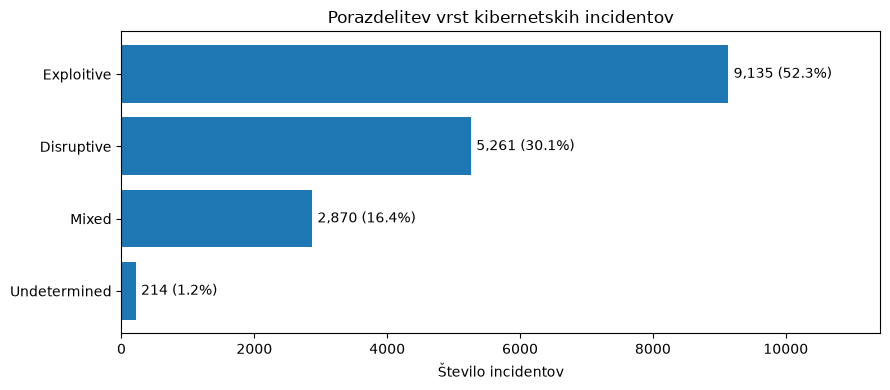

In [7]:

counts = df["event_type"].value_counts()

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(counts.index, counts.values)

ax.invert_yaxis()
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("Število incidentov")
ax.set_title("Porazdelitev vrst kibernetskih incidentov")

# Število in delež posamezne kategorije
for bar, n in zip(bars, counts.values):
    ax.text(n + 80, bar.get_y() + bar.get_height() / 2,
            f"{n:,} ({n / len(df):.1%})", va="center")

plt.tight_layout()
plt.show()


#### Ciljni gospodarski sektorji
Prikaz 15 najpogostejših sektorjev, preostale sem združila pod "Ostali sektorji" samo za vizualizacijo.

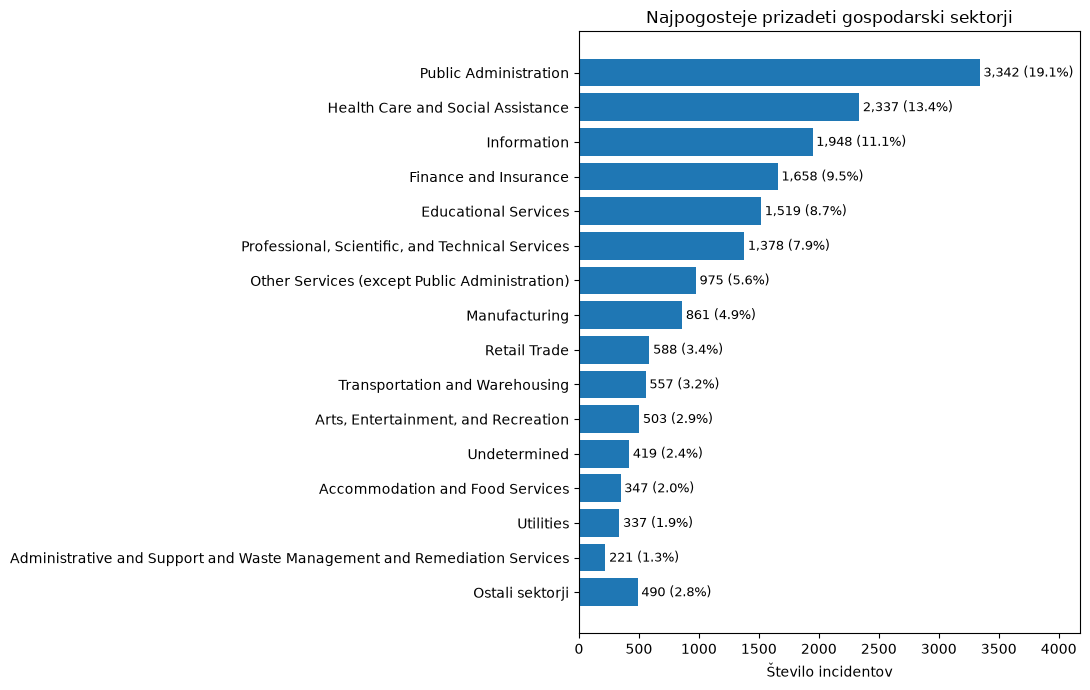

In [8]:

counts = df["industry"].value_counts()

top15 = counts.head(15).copy()
top15.loc["Ostali sektorji"] = counts.iloc[15:].sum()

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(top15.index, top15.values)

ax.invert_yaxis()
ax.set_xlim(0, top15.max() * 1.25)
ax.set_xlabel("Število incidentov")
ax.set_title("Najpogosteje prizadeti gospodarski sektorji")

for bar, n in zip(bars, top15.values):
    ax.text(n + 30, bar.get_y() + bar.get_height() / 2,
            f"{n:,} ({n / len(df):.1%})", va="center", fontsize=9)

plt.tight_layout()
plt.show()


In [9]:
df["industry"].value_counts()

industry
Public Administration                                                       3342
Health Care and Social Assistance                                           2337
Information                                                                 1948
Finance and Insurance                                                       1658
Educational Services                                                        1519
Professional, Scientific, and Technical Services                            1378
Other Services (except Public Administration)                                975
Manufacturing                                                                861
Retail Trade                                                                 588
Transportation and Warehousing                                               557
Arts, Entertainment, and Recreation                                          503
Undetermined                                                                 419
Accommodation and F

Pri spremenljivki `industry` se pojavljajo vsebinsko enake kategorije z različnim zapisom, na primer razlike v velikosti začetnic ali manjše razlike v poimenovanju. Pred nadaljnjo analizo bo zato potrebna standardizacija teh oznak, da bodo frekvence sektorjev pravilno združene.

#### Vrste napadalcev
Prikaz vseh devetih izvirnih kategorij actor_type.

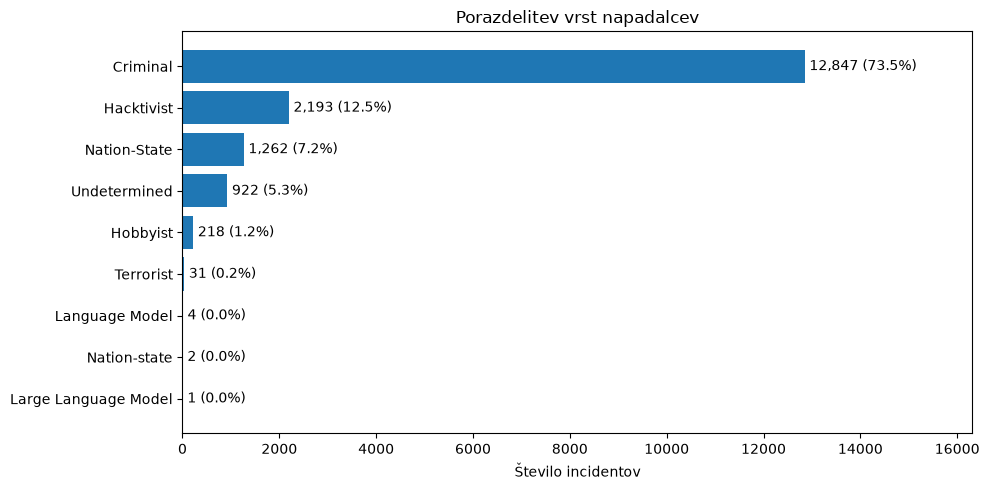

In [10]:

counts = df["actor_type"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(counts.index, counts.values)

ax.invert_yaxis()
ax.set_xlim(0, counts.max() * 1.27)
ax.set_xlabel("Število incidentov")
ax.set_title("Porazdelitev vrst napadalcev")

for bar, n in zip(bars, counts.values):
    ax.text(n + 100, bar.get_y() + bar.get_height() / 2,
            f"{n:,} ({n / len(df):.1%})", va="center")

plt.tight_layout()
plt.show()


In [11]:
df[df["actor_type"] == "Large Language Model" ]["country"]

17410    Australia
Name: country, dtype: str

#### Motivi kibernetskih incidentov

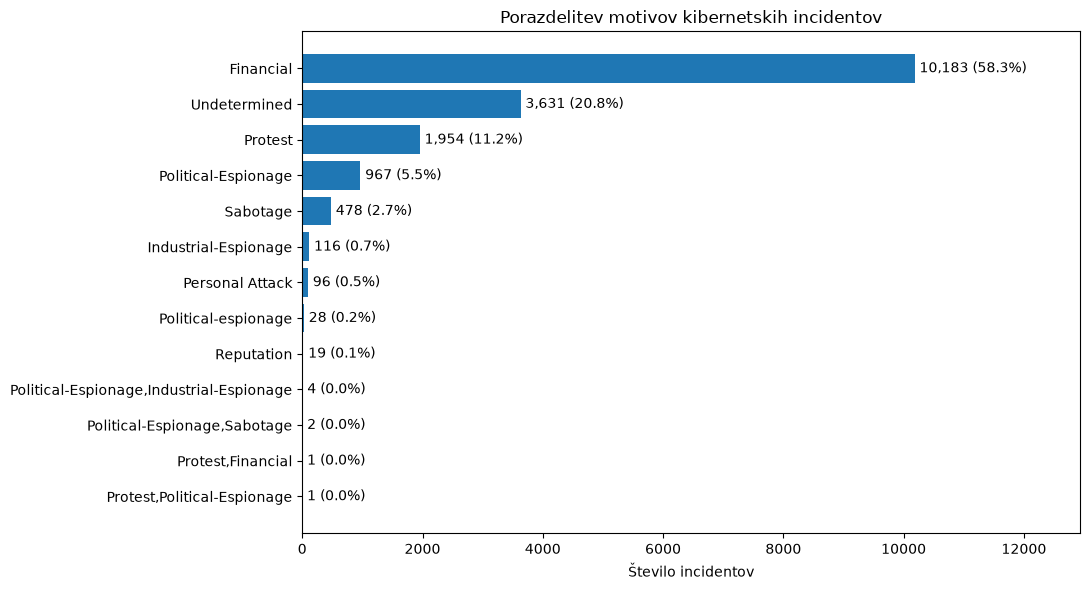

In [12]:

counts = df["motive"].value_counts()

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(counts.index, counts.values)

ax.invert_yaxis()
ax.set_xlim(0, counts.max() * 1.27)
ax.set_xlabel("Število incidentov")
ax.set_title("Porazdelitev motivov kibernetskih incidentov")

for bar, n in zip(bars, counts.values):
    ax.text(n + 80, bar.get_y() + bar.get_height() / 2,
            f"{n:,} ({n / len(df):.1%})", va="center")

plt.tight_layout()
plt.show()



#### Numerične spremenljivke

Preverimo zalogo vrednosti numeričnih spremenljivk in ločimo časovne podatke, šifrirane kategorije ter binarne oznake.


In [13]:

# Izberemo vse numerične stolpce
num_cols = df.select_dtypes(include="number").columns

# Pregled zaloge vrednosti
num_summary = pd.DataFrame({
    "Tip": df[num_cols].dtypes.astype(str),
    "Različne vrednosti": df[num_cols].nunique(),
    "Minimum": df[num_cols].min(),
    "Maksimum": df[num_cols].max()
})

display(num_summary)


,Tip,Različne vrednosti,Minimum,Maksimum
original_method,int64,2,0,1
year,int64,13,2014,2026
month,int64,12,1,12
industry_code,int64,29,11,99
nato,int64,2,0,1
eu,int64,2,0,1
shanghai_coop,int64,2,0,1
oas,int64,2,0,1
mercosur,int64,2,0,1
au,int64,2,0,1


#### Incidenti glede na članstvo v organizacijah

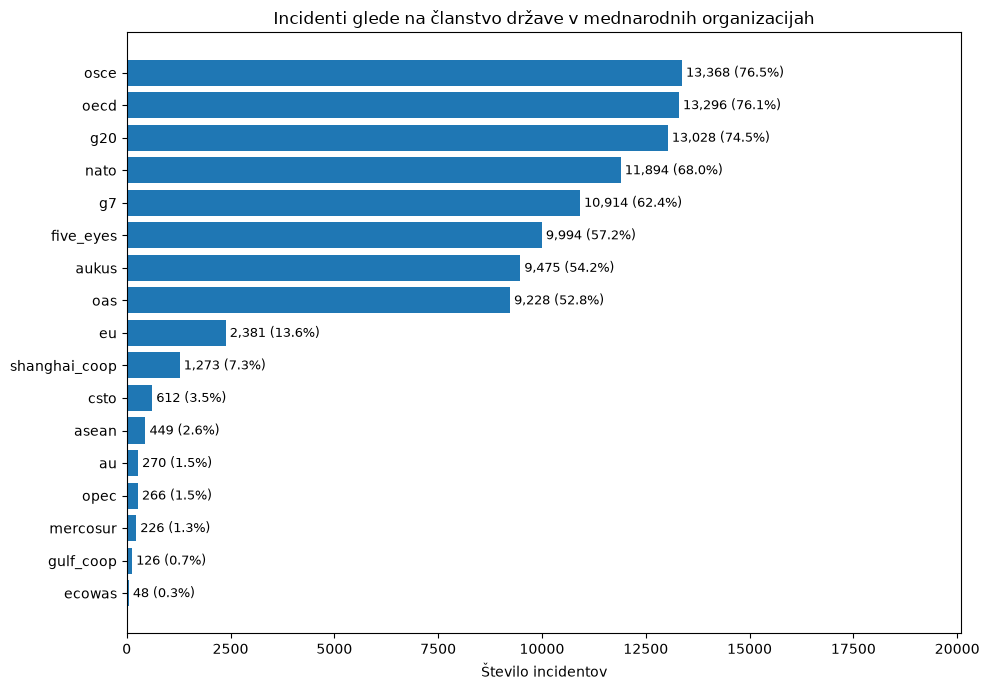

In [14]:

# Binarne oznake mednarodnih organizacij
org_cols = [
    "nato", "eu", "shanghai_coop", "oas", "mercosur",
    "au", "ecowas", "asean", "opec", "gulf_coop",
    "g7", "g20", "aukus", "csto", "oecd", "osce",
    "five_eyes"
]

# Število incidentov z oznako članstva (1)
counts = df[org_cols].sum().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(counts.index, counts.values)

ax.set_xlim(0, len(df) * 1.15)
ax.set_xlabel("Število incidentov")
ax.set_title("Incidenti glede na članstvo države v mednarodnih organizacijah")

for bar, n in zip(bars, counts.values):
    ax.text(n + 100, bar.get_y() + bar.get_height() / 2,
            f"{n:,} ({n / len(df):.1%})", va="center", fontsize=9)

plt.tight_layout()
plt.show()


**Opomba**:Večina zabeleženih incidentov je povezana z državami, označenimi kot članice OSCE (76,5 %), OECD (76,1 %) in G20 (74,5 %). Ker lahko posamezna država pripada več organizacijam, se kategorije prekrivajo in njihovi deleži ne predstavljajo medsebojno izključujočih se skupin. Rezultati prikazujejo porazdelitev zabeleženih incidentov glede na oznake članstva, ne pa stopnje kibernetske ogroženosti posameznih skupin držav.

## 3. Kakovost podatkov

Preverimo popolnost, podvojitve in konsistentnost zapisov ter ocenimo omejitve podatkovne zbirke za nadaljnjo analizo.


### 3.1 Manjkajoče in neznane vrednosti

Preverimo popolnost posameznih spremenljivk in ločeno obravnavamo manjkajoče vrednosti ter eksplicitne oznake neznanih podatkov.


In [15]:

# Število in delež manjkajočih vrednosti po stolpcih
missing_summary = pd.DataFrame({
    "Manjkajoči zapisi": df.isna().sum(),
    "Delež (%)": df.isna().mean() * 100
})

missing_summary = missing_summary.sort_values(
    "Delež (%)", ascending=False
)

display(missing_summary.round(2))


,Manjkajoči zapisi,Delež (%)
duration,16434,94.02
magnitude,16411,93.88
scope,16408,93.87
org_data,15386,88.02
cust_data,15364,87.89
ip,15349,87.81
reported_date,14551,83.24
county,9361,53.55
state,9174,52.48
change_log,1039,5.94


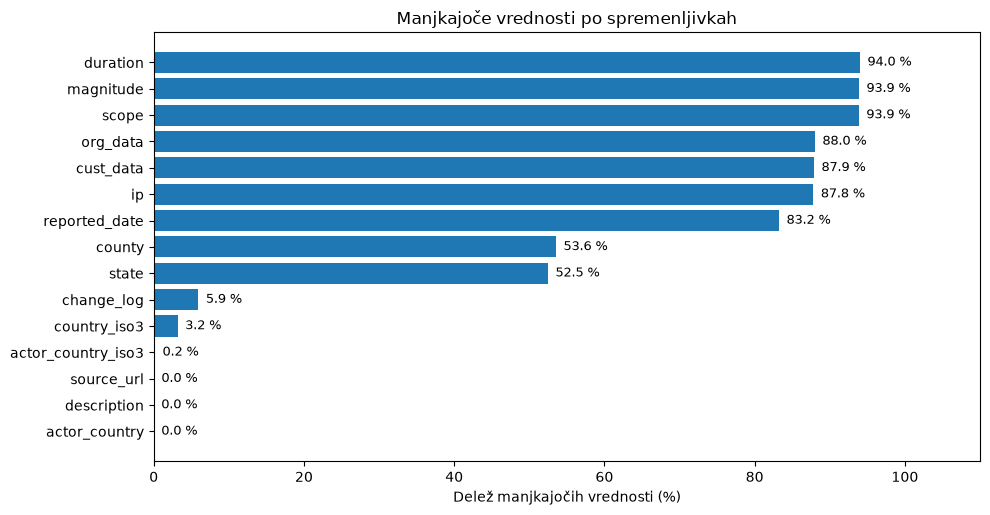

In [16]:
# Izberemo stolpce z vsaj eno manjkajočo vrednostjo
missing_plot = missing_summary[
    missing_summary["Manjkajoči zapisi"] > 0
].sort_values("Delež (%)")

fig, ax = plt.subplots(figsize=(10, max(5, len(missing_plot) * 0.35)))

bars = ax.barh(missing_plot.index, missing_plot["Delež (%)"])

ax.set_xlim(0, 110)
ax.set_xlabel("Delež manjkajočih vrednosti (%)")
ax.set_title("Manjkajoče vrednosti po spremenljivkah")

for bar, pct in zip(bars, missing_plot["Delež (%)"]):
    ax.text(pct + 1, bar.get_y() + bar.get_height() / 2,
            f"{pct:.1f} %", va="center", fontsize=9)

plt.tight_layout()
plt.show()


### 3.2 Podvojeni zapisi in identifikatorji
Preverimo ponavljanje celotnih zapisov in identifikatorjev incidentov ter poiščemo morebitne podvojitve dogodkov.



In [17]:

# Popolnoma identične vrstice
duplicates = df.duplicated().sum()

# Ponovljeni identifikatorji (po prvi pojavitvi)
duplicate_ids = df["slug"].duplicated().sum()

print(f"Popolnoma podvojene vrstice: {duplicates:,}")
print(f"Ponovljeni identifikatorji slug: {duplicate_ids:,}")
print(f"Različni identifikatorji slug: {df['slug'].nunique():,}")


Popolnoma podvojene vrstice: 0
Ponovljeni identifikatorji slug: 0
Različni identifikatorji slug: 17,480


In [18]:

# Prikažemo vse zapise s ponovljenim identifikatorjem
repeated_ids = df[df["slug"].duplicated(keep=False)]

print(f"Zapisov s ponovljenim slug: {len(repeated_ids):,}")

if not repeated_ids.empty:
    display(
        repeated_ids[
            ["slug", "event_date", "organization", "country", "event_type"]
        ].sort_values("slug").head(20)
    )


Zapisov s ponovljenim slug: 0


In [19]:
# Isti datum, organizacija in država
group_cols = ["event_date", "organization", "country"]

duplicate_candidates = (
    df.groupby(group_cols, dropna=False)
    .agg(
        st_zapisov=("slug", "size"),
        razlicnih_vrst=("event_subtype", "nunique"),
        razlicnih_opisov=("description", "nunique")
    )
    .reset_index()
)

# Obdržimo skupine z več kot enim zapisom
duplicate_candidates = (
    duplicate_candidates[duplicate_candidates["st_zapisov"] > 1]
    .sort_values("st_zapisov", ascending=False)
)

print(f"Skupin s potencialnimi podvojitvami: {len(duplicate_candidates):,}")
print(f"Zapisov v teh skupinah: {duplicate_candidates['st_zapisov'].sum():,}")

display(duplicate_candidates.head(20))


Skupin s potencialnimi podvojitvami: 182
Zapisov v teh skupinah: 385


,event_date,organization,country,st_zapisov,razlicnih_vrst,razlicnih_opisov
8574,2022-02-23,Undetermined,Ukraine,10,2,3
7354,2021-03-02,Union Power Ministry (10 Substations and Trans...,India,10,1,1
9480,2022-07-18,Belgium defense and interior ministries,Belgium,4,1,4
8437,2022-01-13,Undetermined,Ukraine,3,1,1
7679,2021-05-02,Undisclosed,Israel,3,1,2
9337,2022-06-29,Undetermined,Norway,3,1,1
4664,2019-06-17,Australian Catholic University (ACU),Australia,2,1,1
4675,2019-06-20,Riviera Beach,United States of America,2,1,1
4685,2019-06-25,Tesco Twitter Account,United Kingdom of Great Britain and Northern I...,2,1,1
4689,2019-06-27,Bitrue,Singapore,2,1,1


In [20]:

# Prikaz zapisov iz petih največjih skupin
selected_groups = duplicate_candidates.head(5)[group_cols]

suspicious_records = df.merge(
    selected_groups,
    on=group_cols,
    how="inner"
)

display(
    suspicious_records[
        ["slug", "event_date", "organization", "country",
         "event_type", "event_subtype", "description"]
    ].sort_values(["event_date", "organization"])
)


,slug,event_date,organization,country,event_type,event_subtype,description
0,3405f3aefb6c901e,2021-03-02,Union Power Ministry (10 Substations and Trans...,India,Disruptive,Physical Attack,NCIIPC informed [Power Ministry] through a mai...
1,86cdbe40f332bb08,2021-03-02,Union Power Ministry (10 Substations and Trans...,India,Disruptive,Physical Attack,NCIIPC informed [Power Ministry] through a mai...
2,8b12d8f17c81fa3d,2021-03-02,Union Power Ministry (10 Substations and Trans...,India,Disruptive,Physical Attack,NCIIPC informed [Power Ministry] through a mai...
3,af20b015e54dfe0a,2021-03-02,Union Power Ministry (10 Substations and Trans...,India,Disruptive,Physical Attack,NCIIPC informed [Power Ministry] through a mai...
4,5ad9cbb57019187f,2021-03-02,Union Power Ministry (10 Substations and Trans...,India,Disruptive,Physical Attack,NCIIPC informed [Power Ministry] through a mai...
5,057614f3c2044c85,2021-03-02,Union Power Ministry (10 Substations and Trans...,India,Disruptive,Physical Attack,NCIIPC informed [Power Ministry] through a mai...
6,d923f8b96e2aac5a,2021-03-02,Union Power Ministry (10 Substations and Trans...,India,Disruptive,Physical Attack,NCIIPC informed [Power Ministry] through a mai...
7,40d8bd4603c69c81,2021-03-02,Union Power Ministry (10 Substations and Trans...,India,Disruptive,Physical Attack,NCIIPC informed [Power Ministry] through a mai...
8,e1dc46ff22e7821c,2021-03-02,Union Power Ministry (10 Substations and Trans...,India,Disruptive,Physical Attack,NCIIPC informed [Power Ministry] through a mai...
9,62bf494f1b7cb99e,2021-03-02,Union Power Ministry (10 Substations and Trans...,India,Disruptive,Physical Attack,NCIIPC informed [Power Ministry] through a mai...


In [21]:

# Strožji kriterij za iskanje potencialnih podvojitev
cols = [
    "event_date", "organization", "country",
    "event_type", "event_subtype", "description"
]

# Izločimo zapise z neznano organizacijo ali opisom
valid = df[
    df["organization"].notna()
    & ~df["organization"].isin(["Undetermined", "Undisclosed"])
    & df["description"].notna()
]

# Poiščemo zapise z enakimi vsebinskimi podatki
exact_candidates = valid[valid.duplicated(subset=cols, keep=False)]

print(f"Zapisov z enakimi ključnimi podatki: {len(exact_candidates):,}")
print(f"Različnih skupin: {exact_candidates.groupby(cols).ngroups:,}")

display(
    exact_candidates[
        ["slug", "event_date", "organization", "country",
         "event_type", "event_subtype", "description"]
    ].sort_values(cols).head(20)
)


Zapisov z enakimi ključnimi podatki: 230
Različnih skupin: 111


,slug,event_date,organization,country,event_type,event_subtype,description
455,9380971a23c1eefb,2014-08-25,Bank of Israel,Israel,Disruptive,External Denial of Service,"In name of #OpSaveGaza, the Anonymous collecti..."
456,d0a6603ecb21da6f,2014-08-25,Bank of Israel,Israel,Disruptive,External Denial of Service,"In name of #OpSaveGaza, the Anonymous collecti..."
2386,a1f30931849c1180,2016-10-19,AdultFriendFinder,United States of America,Exploitive,Exploitation of Application Server,A hacker known as Revolver or 1x0123 claims to...
2387,1c78e9d9452ccf16,2016-10-19,AdultFriendFinder,United States of America,Exploitive,Exploitation of Application Server,A hacker known as Revolver or 1x0123 claims to...
4664,e61a3f8fd31e2ddf,2019-06-15,Missouri Southern State University (MSSU),United States of America,Exploitive,Exploitation of End Hosts,Missouri Southern State University (MSSU) stat...
4665,ee0abe050074aceb,2019-06-15,Missouri Southern State University (MSSU),United States of America,Exploitive,Exploitation of End Hosts,Missouri Southern State University (MSSU) stat...
4670,db7ecfdfcbff0f36,2019-06-17,Australian Catholic University (ACU),Australia,Exploitive,Exploitation of End Hosts,Australian Catholic University (ACU) reveals t...
4671,c1b17c65e76e1c07,2019-06-17,Australian Catholic University (ACU),Australia,Exploitive,Exploitation of End Hosts,Australian Catholic University (ACU) reveals t...
4682,ee18aaeaf1c93f65,2019-06-20,Riviera Beach,United States of America,Disruptive,Data Attack,"Riviera Beach agrees to pay $600,000 in ransom..."
4683,30d1b946aa1db251,2019-06-20,Riviera Beach,United States of America,Disruptive,Data Attack,"Riviera Beach agrees to pay $600,000 in ransom..."


In [22]:

# Preverimo, ali se potencialne podvojitve razlikujejo
# po dodatnih pomembnih spremenljivkah.

additional_cols = [
    "actor", "actor_type", "motive",
    "industry", "source_url", "original_method"
]

comparison = (
    exact_candidates.groupby(cols, dropna=False)[additional_cols]
    .nunique(dropna=False)
)

# Število skupin, kjer se posamezna spremenljivka razlikuje
different_values = (comparison > 1).sum()

display(
    different_values.rename("Skupine z različnimi vrednostmi").to_frame()
)


,Skupine z različnimi vrednostmi
actor,3
actor_type,0
motive,0
industry,0
source_url,1
original_method,0


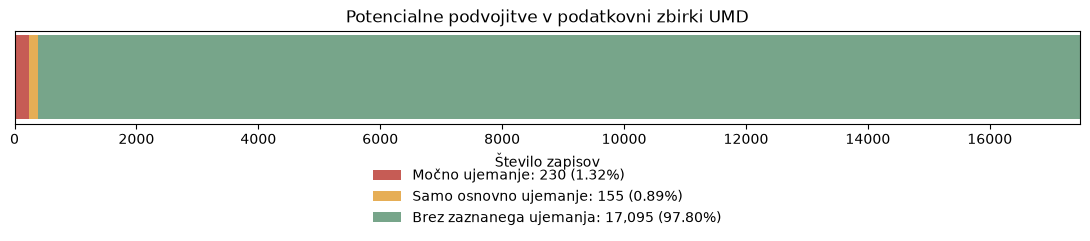

In [23]:

# Število zapisov po stopnji ujemanja
n_total = len(df)
n_strict = len(exact_candidates)
n_broad = int(duplicate_candidates["st_zapisov"].sum())

values = [
    n_strict,
    n_broad - n_strict,
    n_total - n_broad
]

labels = [
    "Močno ujemanje",
    "Samo osnovno ujemanje",
    "Brez zaznanega ujemanja"
]

colors = ["#c65c55", "#e6ae56", "#77a58a"]

# Sestavljeni vodoravni stolpec
fig, ax = plt.subplots(figsize=(11, 3))
left = 0

for n, label, color in zip(values, labels, colors):
    ax.barh(0, n, left=left, color=color, height=0.45,
            label=f"{label}: {n:,} ({n / n_total:.2%})")
    left += n

ax.set_xlim(0, n_total)
ax.set_yticks([])
ax.set_xlabel("Število zapisov")
ax.set_title("Potencialne podvojitve v podatkovni zbirki UMD")

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35),
          ncol=1, frameon=False)

plt.tight_layout()
plt.show()



Pri 385 zapisih (2,20 %) je bilo zaznano ujemanje datuma, organizacije in države, od tega ima 230 zapisov (1,32 %) enake tudi ključne vsebinske podatke. Kljub enoličnim identifikatorjem `slug` zato obstaja možnost večkratnega evidentiranja posameznih incidentov. Potencialne podvojitve je treba preveriti pred nadaljnjo analizo in morebitnim odstranjevanjem.


### 3.3 Nepravilne in neskladne vrednosti

- Undetermined – ni bilo mogoče določiti.
- Undisclosed – informacija ni razkrita.
- Unknown – neznano.

In [24]:

# Oznake, ki lahko predstavljajo neznane podatke
unknown_labels = ["Undetermined", "Undisclosed", "Unknown"]

# Pregled ključnih kategoričnih spremenljivk
check_cols = [
    "country", "organization", "actor", "actor_type",
    "industry", "event_type", "event_subtype", "motive"
]

unknown_summary = pd.DataFrame({
    "Neznani zapisi": [
        df[col].astype("string").str.strip().str.lower()
        .isin([label.lower() for label in unknown_labels]).sum()
        for col in check_cols
    ]
}, index=check_cols)

unknown_summary["Delež (%)"] = (
    unknown_summary["Neznani zapisi"] / len(df) * 100
)

display(unknown_summary.sort_values("Delež (%)", ascending=False).round(2))


,Neznani zapisi,Delež (%)
actor,10005,57.24
motive,3631,20.77
event_subtype,1078,6.17
actor_type,922,5.27
country,645,3.69
industry,419,2.40
event_type,214,1.22
organization,62,0.35


#### Delež neznanih vrednosti

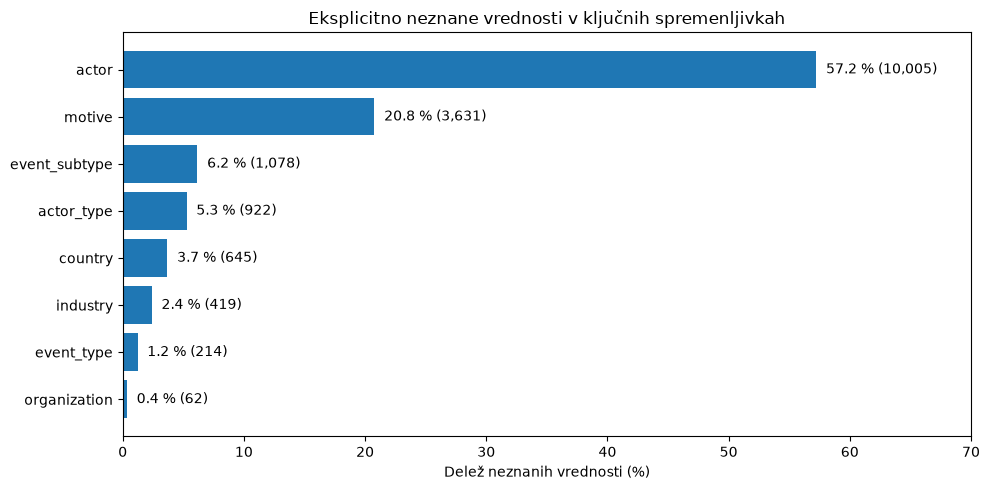

In [25]:

# Razvrstitev spremenljivk po deležu neznanih vrednosti
unknown_plot = unknown_summary.sort_values("Delež (%)")

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(unknown_plot.index, unknown_plot["Delež (%)"])

ax.set_xlim(0, 70)
ax.set_xlabel("Delež neznanih vrednosti (%)")
ax.set_title("Eksplicitno neznane vrednosti v ključnih spremenljivkah")

# Prikaz odstotkov in števila zapisov
for bar, (n, pct) in zip(bars, unknown_plot[
    ["Neznani zapisi", "Delež (%)"]
].to_numpy()):
    ax.text(pct + 0.8, bar.get_y() + bar.get_height() / 2,
            f"{pct:.1f} % ({int(n):,})", va="center")

plt.tight_layout()
plt.show()


Priprava podatkov za graf

In [26]:

# Vrste manjkajočih in neznanih vrednosti
types = ["NaN/NA", "NaT", "Undetermined", "Undisclosed", "Unknown"]

quality_summary = pd.DataFrame(0, index=df.columns, columns=types)

for col in df.columns:
    series = df[col]

    # Dejanske manjkajoče vrednosti ločimo po tipu stolpca
    missing = series.isna().sum()

    if pd.api.types.is_datetime64_any_dtype(series):
        quality_summary.loc[col, "NaT"] = missing
    else:
        quality_summary.loc[col, "NaN/NA"] = missing

    # Eksplicitne oznake neznanih vrednosti
    text = series.astype("string").str.strip().str.casefold()

    for label in ["Undetermined", "Undisclosed", "Unknown"]:
        quality_summary.loc[col, label] = (
            text == label.casefold()
        ).sum()

# Izračunamo skupno število in delež neznanih vrednosti
quality_summary["Skupaj"] = quality_summary[types].sum(axis=1)
quality_summary["Delež (%)"] = quality_summary["Skupaj"] / len(df) * 100

# Prikažemo samo spremenljivke z vsaj eno takšno vrednostjo
quality_summary = quality_summary[
    quality_summary["Skupaj"] > 0
].sort_values("Delež (%)", ascending=False)

display(quality_summary.round(2))


,NaN/NA,NaT,Undetermined,Undisclosed,Unknown,Skupaj,Delež (%)
duration,16434,0,383,0,0,16817,96.21
scope,16408,0,111,0,0,16519,94.50
magnitude,16411,0,107,0,0,16518,94.50
org_data,15386,0,146,0,0,15532,88.86
cust_data,15364,0,123,0,0,15487,88.60
ip,15349,0,86,0,0,15435,88.30
reported_date,0,14551,0,0,0,14551,83.24
actor_country_iso3,30,0,13363,0,0,13393,76.62
actor_country,1,0,13392,0,0,13393,76.62
county,9361,0,1815,0,0,11176,63.94


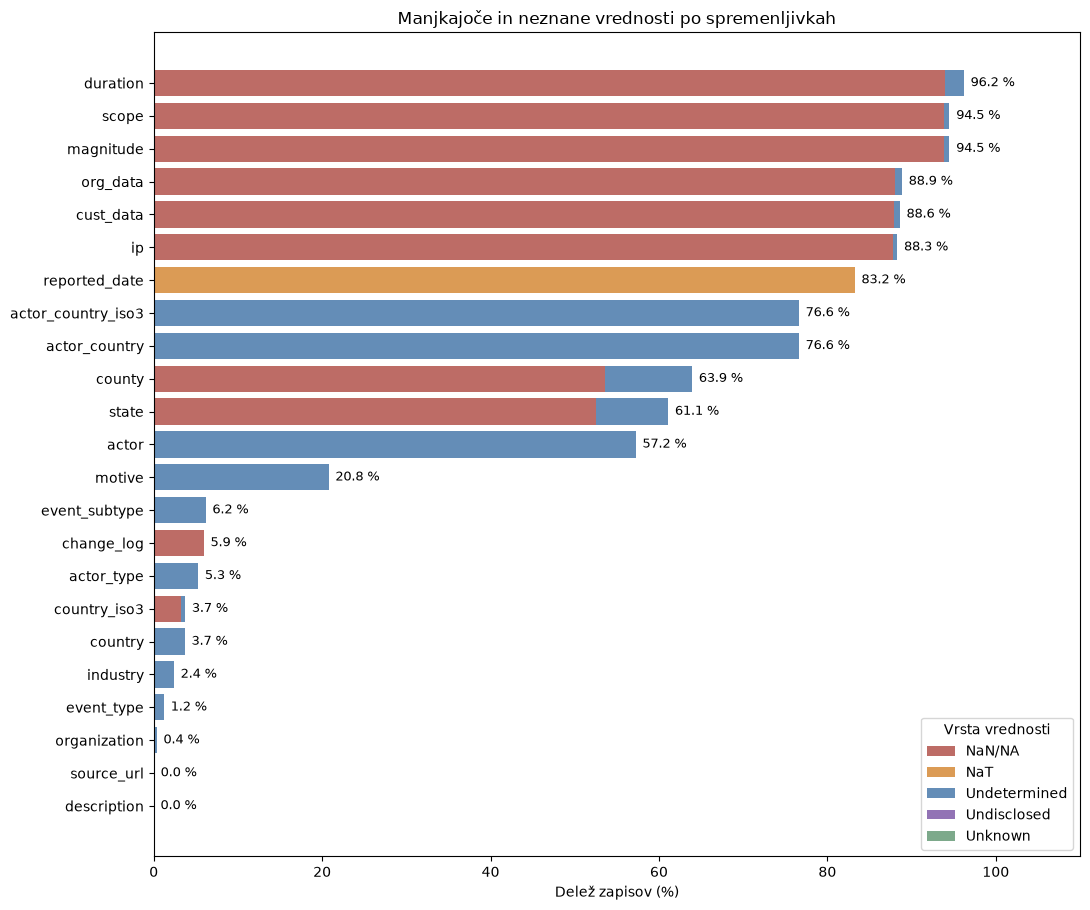

In [27]:

# Deleži posameznih vrst neznanih vrednosti
plot_data = quality_summary[types] / len(df) * 100
plot_data = plot_data.iloc[::-1]

colors = {
    "NaN/NA": "#bd6c66",
    "NaT": "#db9b55",
    "Undetermined": "#648db7",
    "Undisclosed": "#9273b5",
    "Unknown": "#7da98b"
}

fig, ax = plt.subplots(
    figsize=(11, max(6, len(plot_data) * 0.4))
)

left = pd.Series(0.0, index=plot_data.index)

# Vsaka vrsta neznanih vrednosti je svoj del stolpca
for label in types:
    ax.barh(
        plot_data.index,
        plot_data[label],
        left=left,
        label=label,
        color=colors[label]
    )
    left += plot_data[label]

# Skupni delež na koncu vsakega stolpca
for i, total in enumerate(left):
    ax.text(total + 0.8, i, f"{total:.1f} %", va="center", fontsize=9)

ax.set_xlim(0, 110)
ax.set_xlabel("Delež zapisov (%)")
ax.set_title("Manjkajoče in neznane vrednosti po spremenljivkah")
ax.legend(title="Vrsta vrednosti", loc="lower right")

plt.tight_layout()
plt.show()



#### Neenotne kategorije in večvrednostni zapisi

Preverimo nedoslednosti v poimenovanju kategorij in prisotnost več vrednosti v posameznih celicah, ki lahko vplivajo na pravilnost frekvenčnih analiz.


#### Večvrednostni zapisi

In [28]:

# Spremenljivke, pri katerih smo opazili več kategorij v eni celici
multi_cols = ["event_subtype", "motive"]

multi_summary = pd.DataFrame({
    "Večvrednostni zapisi": [
        df[col].astype("string").str.contains(",", regex=False, na=False).sum()
        for col in multi_cols
    ]
}, index=multi_cols)

multi_summary["Delež (%)"] = (
    multi_summary["Večvrednostni zapisi"] / len(df) * 100
)

display(multi_summary.round(2))


,Večvrednostni zapisi,Delež (%)
event_subtype,1785,10.21
motive,8,0.05


#### Neenotna poimenovanja

In [29]:

check_cols = ["industry", "actor_type", "event_subtype", "motive"]

for col in check_cols:
    original = df[col].dropna().astype(str)
    normalized = original.str.strip().str.casefold()

    print(
        f"{col}: {original.nunique()} izvirnih kategorij → "
        f"{normalized.nunique()} po osnovni standardizaciji"
    )


industry: 27 izvirnih kategorij → 22 po osnovni standardizaciji
actor_type: 9 izvirnih kategorij → 8 po osnovni standardizaciji
event_subtype: 85 izvirnih kategorij → 79 po osnovni standardizaciji
motive: 13 izvirnih kategorij → 12 po osnovni standardizaciji


Pregled neenotnih kategorij

In [30]:

check_cols = ["industry", "actor_type", "event_subtype", "motive"]

for col in check_cols:
    # Izvirne vrednosti in osnovno poenotena oblika
    categories = df[[col]].drop_duplicates().copy()
    categories["normalized"] = (
        categories[col].astype("string").str.strip().str.casefold()
    )

    # Izberemo samo skupine z več različnimi zapisi
    repeated = categories[
        categories.duplicated("normalized", keep=False)
    ].sort_values("normalized")

    print(f"\n{col} – različice iste kategorije:")
    display(repeated.rename(columns={col: "Izvirni zapis"}))



industry – različice iste kategorije:


,Izvirni zapis,normalized
0,Educational Services,educational services
15841,Educational services,educational services
8,Finance and Insurance,finance and insurance
14039,Finance and insurance,finance and insurance
15002,Finance And Insurance,finance and insurance
84,Health Care and Social Assistance,health care and social assistance
15001,Health Care And Social Assistance,health care and social assistance
15,Other Services (except Public Administration),other services (except public administration)
15027,Other Services (Except Public Administration),other services (except public administration)



actor_type – različice iste kategorije:


,Izvirni zapis,normalized
87,Nation-State,nation-state
16780,Nation-state,nation-state



event_subtype – različice iste kategorije:


,Izvirni zapis,normalized
948,"Data Attack,Exploitation of Application Server","data attack,exploitation of application server"
15024,"Data Attack,Exploitation Of Application Server","data attack,exploitation of application server"
1,Exploitation of Application Server,exploitation of application server
14729,Exploitation of application server,exploitation of application server
15001,Exploitation Of Application Server,exploitation of application server
102,Exploitation of Network Infrastructure,exploitation of network infrastructure
15050,Exploitation Of Network Infrastructure,exploitation of network infrastructure
4,External Denial of Service,external denial of service
15000,External Denial Of Service,external denial of service
16265,External denial of service,external denial of service



motive – različice iste kategorije:


,Izvirni zapis,normalized
74,Political-Espionage,political-espionage
15294,Political-espionage,political-espionage


Pri industry sem že prej opazila tudi 'Real Estate and Rental and Leasing' ter 'Real Estate Rental and Leasing'. Te razlike osnovna standardizacija s casefold() ne zazna, zato bo potrebna še ročna presoja.

#### Skladnost datumov

In [31]:

# Preverimo ujemanje leta in meseca z datumom incidenta
year_mismatch = df["event_date"].dt.year != df["year"]
month_mismatch = df["event_date"].dt.month != df["month"]

print(f"Neskladno leto: {year_mismatch.sum():,}")
print(f"Neskladen mesec: {month_mismatch.sum():,}")
print(f"Vsaj eno neskladje: {(year_mismatch | month_mismatch).sum():,}")

# Prikažemo primere morebitnih neskladij
display(
    df.loc[
        year_mismatch | month_mismatch,
        ["slug", "event_date", "year", "month"]
    ].head(15)
)


Neskladno leto: 0
Neskladen mesec: 2
Vsaj eno neskladje: 2


,slug,event_date,year,month
16567,3rtd1f0c3b9e7a52,2026-02-27,2026,3
17412,q6H3dM9rV2kL8pC5,2026-07-26,2026,8



#### Skladnost državnih kod in sektorskih klasifikacij

Preverimo pravilnost in popolnost državnih oznak ter skladnost imen sektorjev z njihovimi kodami.


In [32]:

# Zapisi brez kode ISO3
missing_iso = df[df["country_iso3"].isna()]

# Pregled držav, pri katerih koda manjka
iso_summary = (
    missing_iso["country"]
    .value_counts(dropna=False)
    .rename_axis("Država")
    .reset_index(name="Število zapisov")
)

print(f"Zapisov brez ISO3: {len(missing_iso):,}")
print(f"Različnih oznak držav: {len(iso_summary)}")

display(iso_summary)


Zapisov brez ISO3: 557
Različnih oznak držav: 5


,Država,Število zapisov
0,Undetermined,550
1,European Union,3
2,Kosovo,2
3,Saint Thomas,1
4,Micronesia,1


In [33]:

# Upoštevamo samo zapise z določeno kodo ISO3
countries = df.dropna(subset=["country_iso3"])

# Število različnih kod za posamezno državo
codes_per_country = countries.groupby("country")["country_iso3"].nunique()

# Število različnih imen držav za posamezno kodo
countries_per_code = countries.groupby("country_iso3")["country"].nunique()

print("Države z več različnimi kodami ISO3:")
display(codes_per_country[codes_per_country > 1])

print("Kode ISO3 z več različnimi imeni držav:")
display(countries_per_code[countries_per_code > 1])


Države z več različnimi kodami ISO3:


Series([], Name: country_iso3, dtype: int64)

Kode ISO3 z več različnimi imeni držav:


country_iso3
GBR    2
MDA    2
MKD    2
PSE    2
RUS    2
TUR    2
USA    2
Name: country, dtype: int64

In [34]:

# Kode ISO3, povezane z več različnimi imeni držav
problem_codes = countries_per_code[countries_per_code > 1].index

# Prikažemo različna imena in število zapisov za vsako kodo
country_variants = (
    countries[countries["country_iso3"].isin(problem_codes)]
    .groupby(["country_iso3", "country"])
    .size()
    .reset_index(name="Število zapisov")
    .sort_values(["country_iso3", "Število zapisov"],
                 ascending=[True, False])
)

display(country_variants)


,country_iso3,country,Število zapisov
1,GBR,United Kingdom of Great Britain and Northern I...,876
0,GBR,United Kingdom Of Great Britain And Northern I...,3
3,MDA,Moldova (the Republic of),23
2,MDA,Moldova,1
4,MKD,North Macedonia,1
5,MKD,Republic of North Macedonia,1
7,PSE,"Palestine, State of",7
6,PSE,Palestine,1
9,RUS,Russian Federation,505
8,RUS,Russia,3


#### Skladnost sektorjev in njihovih kod

In [35]:

# Osnovna standardizacija imen sektorjev za preverjanje
industry_check = df[["industry_code", "industry"]].copy()

industry_check["industry_normalized"] = (
    industry_check["industry"].astype("string")
    .str.strip()
    .str.casefold()
)

# Koliko različnih imen pripada posamezni kodi?
names_per_code = (
    industry_check.groupby("industry_code")["industry_normalized"]
    .nunique()
)

# Koliko različnih kod pripada posameznemu imenu?
codes_per_name = (
    industry_check.groupby("industry_normalized")["industry_code"]
    .nunique()
)

print("Kode z več različnimi imeni sektorjev:")
display(names_per_code[names_per_code > 1])

print("Sektorji z več različnimi kodami:")
display(codes_per_name[codes_per_name > 1])


Kode z več različnimi imeni sektorjev:


industry_code
53    2
54    2
92    2
Name: industry_normalized, dtype: int64

Sektorji z več različnimi kodami:


industry_normalized
manufacturing                                       3
professional, scientific, and technical services    2
public administration                               6
retail trade                                        2
transportation and warehousing                      2
Name: industry_code, dtype: int64

In [36]:

# Sektorji, povezani z več različnimi kodami
problem_industries = codes_per_name[codes_per_name > 1].index

# Pregled konkretnih kombinacij in njihove pogostosti
industry_variants = (
    industry_check[
        industry_check["industry_normalized"].isin(problem_industries)
    ]
    .groupby(["industry_normalized", "industry_code"])
    .size()
    .reset_index(name="Število zapisov")
    .sort_values(["industry_normalized", "Število zapisov"],
                 ascending=[True, False])
)

display(industry_variants)


,industry_normalized,industry_code,Število zapisov
0,manufacturing,31,657
2,manufacturing,33,168
1,manufacturing,32,36
3,"professional, scientific, and technical services",54,1377
4,"professional, scientific, and technical services",92,1
6,public administration,92,3337
5,public administration,54,1
7,public administration,93,1
8,public administration,94,1
9,public administration,95,1



### 3.4 Povzetek ugotovitev o kakovosti podatkov

Pregled 17.480 zapisov podatkovne zbirke UMD je pokazal naslednje:

1. **Manjkajoče in neznane vrednosti:** največ nepopolnih podatkov je pri trajanju, obsegu in resnosti incidentov ter identiteti in državi izvora napadalcev. Vrste incidentov, ciljni sektorji in države žrtev so bistveno bolje določeni.
2. **Podvojitve:** odkritih je bilo 230 zapisov v 111 skupinah z močnim vsebinskim ujemanjem. Gre za potencialne podvojitve, ki zahtevajo dodatno preverjanje.
3. **Neenotne kategorije:** pri sektorjih, vrstah napadalcev, podvrstah incidentov in motivih se pojavljajo različna poimenovanja istih kategorij.
4. **Večvrednostni zapisi:** 1.785 incidentov (10,21 %) vsebuje več podvrst, 8 incidentov (0,05 %) pa več motivov.
5. **Datumska neskladja:** odkriti sta bili dve neskladji med datumom incidenta in zapisanim mesecem.
6. **Geografski podatki:** manjka 557 kod ISO3, večinoma zaradi nedoločene države. Pri sedmih kodah se pojavljajo različna poimenovanja iste države.
7. **Sektorske kode:** več različnih kod pri proizvodnji, trgovini in prometu je skladnih s klasifikacijo NAICS. Ugotovljenih je bilo šest potencialno napačnih kombinacij sektorja in kode.

Pred časovno in geografsko analizo je zato potrebno standardizirati kategorije in državne oznake, ustrezno obravnavati večvrednostne zapise ter preveriti potencialne podvojitve in neskladja.



## 4. Čiščenje in priprava podatkov

Na podlagi ugotovljenih težav pripravimo konsistentno podatkovno zbirko za nadaljnjo analizo. Izvirne podatke ohranimo, vse spremembe pa izvedemo na ločeni delovni kopiji.

### 4.1 Priprava delovne kopije

Ustvarimo kopijo podatkov in zabeležimo začetno stanje, da bomo lahko preverili učinke čiščenja.


In [37]:
# Neodvisna kopija izvirnih podatkov
df_clean = df.copy(deep=True)

# Začetno stanje pred čiščenjem
initial_rows = len(df_clean)
initial_cols = len(df_clean.columns)
initial_slugs = df_clean["slug"].nunique()

print(f"Število incidentov: {initial_rows:,}")
print(f"Število stolpcev: {initial_cols}")
print(f"Enolični identifikatorji: {initial_slugs:,}")
print(f"Kopija je ustvarjena: {df_clean is not df}")


Število incidentov: 17,480
Število stolpcev: 46
Enolični identifikatorji: 17,480
Kopija je ustvarjena: True


### 4.2 Standardizacija kategoričnih vrednosti

Poenotimo različne zapise istih kategorij pri sektorjih, vrstah napadalcev, podvrstah incidentov in motivih. Standardizacija ohranja vsebinski pomen kategorij in ne spreminja števila incidentov.


In [38]:
# Kategorične spremenljivke za standardizacijo
category_cols = ["industry", "actor_type", "event_subtype", "motive"]

# Kanonični zapis izberemo kot najpogostejšo izvirno različico
for col in category_cols:
    original = df_clean[col].astype("string").str.strip()
    normalized = original.str.casefold()

    canonical = (
        pd.DataFrame({"original": original, "normalized": normalized})
        .groupby("normalized")["original"]
        .agg(lambda values: values.value_counts().index[0])
    )

    df_clean[col] = normalized.map(canonical)

# Primerjava števila različnih kategorij
comparison = pd.DataFrame({
    "Pred čiščenjem": df[category_cols].nunique(),
    "Po čiščenju": df_clean[category_cols].nunique()
})

display(comparison)
print(f"Število incidentov po standardizaciji: {len(df_clean):,}")


,Pred čiščenjem,Po čiščenju
industry,27,22
actor_type,9,8
event_subtype,85,79
motive,13,12


Število incidentov po standardizaciji: 17,480


In [39]:

# Poiščemo sektorje, ki vsebujejo "Real Estate"
real_estate = df_clean[
    df_clean["industry"].str.contains("Real Estate", case=False, na=False)
]

# Pregled poimenovanj in pripadajočih kod
display(
    real_estate.groupby(["industry", "industry_code"])
    .size()
    .reset_index(name="Število zapisov")
    .sort_values("Število zapisov", ascending=False)
)


,industry,industry_code,Število zapisov
1,Real Estate and Rental and Leasing,53,99
0,Real Estate Rental and Leasing,53,1


In [40]:

# Pregled vseh sektorjev in pripadajočih kod
industry_overview = (
    df_clean.groupby(["industry", "industry_code"], dropna=False)
    .size()
    .reset_index(name="Število zapisov")
    .sort_values(["industry", "industry_code"])
)

display(industry_overview)

print(f"Različnih imen sektorjev: {df_clean['industry'].nunique()}")
print(f"Različnih kod sektorjev: {df_clean['industry_code'].nunique()}")


,industry,industry_code,Število zapisov
0,Accommodation and Food Services,72,347
1,Administrative and Support and Waste Managemen...,56,221
2,"Agriculture, Forestry, Fishing and Hunting",11,21
3,"Arts, Entertainment, and Recreation",71,503
4,Construction,23,62
5,Educational Services,61,1521
6,Finance and Insurance,52,1682
7,Health Care and Social Assistance,62,2368
8,Information,51,1948
9,Management of Companies and Enterprises,55,21


Različnih imen sektorjev: 22
Različnih kod sektorjev: 29


#### Poenotenje imena

In [41]:
# Poenotimo različici istega sektorja
df_clean["industry"] = df_clean["industry"].replace({
    "Real Estate Rental and Leasing":
        "Real Estate and Rental and Leasing"
})

# Preverimo rezultat
print("Različnih sektorjev pred čiščenjem:", df["industry"].nunique())
print("Različnih sektorjev po čiščenju:", df_clean["industry"].nunique())
print("Število incidentov:", len(df_clean))


Različnih sektorjev pred čiščenjem: 27
Različnih sektorjev po čiščenju: 21
Število incidentov: 17480


In [42]:
# Poenotimo kategoriji jezikovnih modelov
df_clean["actor_type"] = df_clean["actor_type"].replace({
    "Large Language Model": "Language Model"
})

# Preverjanje
print("Število kategorij:", df_clean["actor_type"].nunique())
print(
    "Incidentov v kategoriji Language Model:",
    (df_clean["actor_type"] == "Language Model").sum()
)


Število kategorij: 7
Incidentov v kategoriji Language Model: 5


In [43]:
# Neskladja med sektorjem in kodo NAICS
mismatch = (
    ((df_clean["industry"] == "Public Administration") &
     (df_clean["industry_code"] != 92))
    |
    ((df_clean["industry"] == "Professional, Scientific, and Technical Services") &
     (df_clean["industry_code"] != 54))
)

suspicious_industries = df_clean.loc[
    mismatch,
    ["slug", "organization", "industry", "industry_code", "description"]
]

print("Potencialno neskladnih zapisov:", len(suspicious_industries))

# Celoten opis je pomemben za presojo posameznega incidenta
with pd.option_context("display.max_colwidth", 250):
    display(suspicious_industries)


Potencialno neskladnih zapisov: 6


,slug,organization,industry,industry_code,description
12860,45c7bce272af2bc1,Organization in the defense sector,"Professional, Scientific, and Technical Services",92,"Germany's federal intelligence agency (BfV) and South Korea's National Intelligence Service (NIS) warn that Lazarus group's ""Operation Dream Job,"" was also used against the defense sector."
14818,n4b7x2v9c6m8q1z3,"Government, tech, academic & telecom entities; global",Public Administration,54,"CrowdStrike reports that multiple Chinese-linked groupsÃ¢â‚¬â€Murky Panda, Genesis Panda, and Glacial PandaÃ¢â‚¬â€have exploited vulnerabilities (e.g., Citrix CVE-2023-3519, Commvault CVE-2025-3928) to deploy the CloudedHope malware for covert ..."
15674,f2e8c0a7b493d61e,Department of Public Works and Highways (DPWH),Public Administration,93,DICT/CICC reported a coordinated wave of cyberattacks on government websites amid Sept 21 rallies.
15675,0a6d1b3f5c8e2d74,Bureau of the Treasury (BTr),Public Administration,94,DICT/CICC reported a coordinated wave of cyberattacks on government websites amid Sept 21 rallies.
15676,1be7406a9dcf3e52,Bureau of Customs (BOC),Public Administration,95,DICT/CICC reported a coordinated wave of cyberattacks on government websites amid Sept 21 rallies.
15677,84cda1f670b2e953,Department of Foreign Affairs (DFA),Public Administration,96,DICT/CICC reported a coordinated wave of cyberattacks on government websites amid Sept 21 rallies.


In [44]:
# Identifikatorji štirih incidentov javne uprave
slugs_to_fix = [
    "f2e8c0a7b493d61e",
    "0a6d1b3f5c8e2d74",
    "1be7406a9dcf3e52",
    "84cda1f670b2e953"
]

# Popravimo samo neskladne kode
mask = df_clean["slug"].isin(slugs_to_fix)

assert mask.sum() == 4
assert (df_clean.loc[mask, "industry"] == "Public Administration").all()
assert set(df_clean.loc[mask, "industry_code"]) == {93, 94, 95, 96}

df_clean.loc[mask, "industry_code"] = 92

# Preverjanje
display(
    df_clean.loc[
        mask, ["slug", "organization", "industry", "industry_code"]
    ]
)


,slug,organization,industry,industry_code
15674,f2e8c0a7b493d61e,Department of Public Works and Highways (DPWH),Public Administration,92
15675,0a6d1b3f5c8e2d74,Bureau of the Treasury (BTr),Public Administration,92
15676,1be7406a9dcf3e52,Bureau of Customs (BOC),Public Administration,92
15677,84cda1f670b2e953,Department of Foreign Affairs (DFA),Public Administration,92


In [45]:

# Ponovno preverimo neskladja med sektorji in kodami
mismatch = (
    ((df_clean["industry"] == "Public Administration") &
     (df_clean["industry_code"] != 92))
    |
    ((df_clean["industry"] == "Professional, Scientific, and Technical Services") &
     (df_clean["industry_code"] != 54))
)

remaining = df_clean.loc[
    mismatch, ["slug", "organization", "industry", "industry_code"]
]

print(f"Preostala neskladja: {len(remaining)}")
display(remaining)


Preostala neskladja: 2


,slug,organization,industry,industry_code
12860,45c7bce272af2bc1,Organization in the defense sector,"Professional, Scientific, and Technical Services",92
14818,n4b7x2v9c6m8q1z3,"Government, tech, academic & telecom entities;...",Public Administration,54



### 4.3 Obravnava večvrednostnih zapisov

Podvrste incidentov in motive, zapisane kot več vrednosti v eni celici, razdelimo v ločeni povezovalni tabeli. Pri tem ohranimo povezavo z identifikatorjem `slug` in ne spreminjamo števila incidentov v glavni zbirki.


#### Razdelitev večvrednostnih zapisov

In [46]:
def create_multivalue_table(data, column):
    # Vsako vrednost razdelimo po vejici
    result = data[["slug", column]].copy()
    result[column] = result[column].astype("string").str.split(",")

    # Vsaka posamezna kategorija dobi svojo vrstico
    result = result.explode(column)

    # Odstranimo odvečne presledke
    result[column] = result[column].str.strip()

    return result.reset_index(drop=True)


df_subtypes = create_multivalue_table(df_clean, "event_subtype")
df_motives = create_multivalue_table(df_clean, "motive")

print("Incidentov v glavni zbirki:", len(df_clean))
print("Vrstic v tabeli podvrst:", len(df_subtypes))
print("Različnih podvrst:", df_subtypes["event_subtype"].nunique())
print("Vrstic v tabeli motivov:", len(df_motives))
print("Različnih motivov:", df_motives["motive"].nunique())


Incidentov v glavni zbirki: 17480
Vrstic v tabeli podvrst: 19347
Različnih podvrst: 15
Vrstic v tabeli motivov: 17488
Različnih motivov: 8


#### Preverjanje povezovalnih tabel

In [47]:
validation = []

for table, col in [
    (df_subtypes, "event_subtype"),
    (df_motives, "motive")
]:
    validation.append({
        "Spremenljivka": col,
        "Število povezav": len(table),
        "Različni incidenti": table["slug"].nunique(),
        "Prazne vrednosti": (
            table[col].isna() | table[col].eq("")
        ).sum(),
        "Podvojene povezave": table.duplicated(
            subset=["slug", col]
        ).sum(),
        "Neznani identifikatorji": (
            ~table["slug"].isin(df_clean["slug"])
        ).sum()
    })

display(pd.DataFrame(validation))


,Spremenljivka,Število povezav,Različni incidenti,Prazne vrednosti,Podvojene povezave,Neznani identifikatorji
0,event_subtype,19347,17480,0,1,0
1,motive,17488,17480,0,0,0


In [48]:

# Poiščemo vse pojavitve podvojene povezave
duplicate_subtypes = df_subtypes[
    df_subtypes.duplicated(
        subset=["slug", "event_subtype"],
        keep=False
    )
]

display(duplicate_subtypes.sort_values(["slug", "event_subtype"]))

# Izvirni zapis za primerjavo
display(
    df.loc[
        df["slug"].isin(duplicate_subtypes["slug"]),
        ["slug", "event_subtype", "description"]
    ]
)


,slug,event_subtype
18756,3czhv3x7fcgtu7fe,Undetermined
18757,3czhv3x7fcgtu7fe,Undetermined


,slug,event_subtype,description
16956,3czhv3x7fcgtu7fe,"Undetermined,Undetermined","The City of Martinsville disclosed that, on or..."


In [49]:
# Odstranimo ponovljene podvrste pri istem incidentu
df_subtypes = df_subtypes.drop_duplicates(
    subset=["slug", "event_subtype"]
).reset_index(drop=True)

# Preverjanje
print("Povezav incident–podvrsta:", len(df_subtypes))
print("Različnih incidentov:", df_subtypes["slug"].nunique())
print("Podvojenih povezav:",
      df_subtypes.duplicated(["slug", "event_subtype"]).sum())


Povezav incident–podvrsta: 19346
Različnih incidentov: 17480
Podvojenih povezav: 0


In [50]:
print("Podvrste incidentov:")
display(df_subtypes["event_subtype"].value_counts().to_frame("Število"))

print("Motivi:")
display(df_motives["motive"].value_counts().to_frame("Število"))


Podvrste incidentov:


,Število
event_subtype,
Exploitation of Application Server,7926
Data Attack,4190
External Denial of Service,1985
Exploitation of End Hosts,1911
Message Manipulation,1417
Undetermined,1147
Internal Denial of Service,249
Exploitation of Sensors,197
Exploitation of Network Infrastructure,120


Motivi:


,Število
motive,
Financial,10184
Undetermined,3631
Protest,1956
Political-Espionage,1002
Sabotage,480
Industrial-Espionage,120
Personal Attack,96
Reputation,19


In [51]:
# Ponovno pripravimo povezovalno tabelo podvrst
df_subtypes = df_clean[["slug", "event_subtype"]].copy()

# Razdelimo po vejici ali podpičju
df_subtypes["event_subtype"] = (
    df_subtypes["event_subtype"]
    .astype("string")
    .str.split(r"[,;]")
)

df_subtypes = df_subtypes.explode("event_subtype")

# Poenotimo presledke
df_subtypes["event_subtype"] = (
    df_subtypes["event_subtype"]
    .str.split()
    .str.join(" ")
)

# Poenotimo znano različico imena
df_subtypes["event_subtype"] = df_subtypes["event_subtype"].replace({
    "Exploitation of Application Servers":
        "Exploitation of Application Server"
})

# Odstranimo morebitne podvojene povezave
df_subtypes = (
    df_subtypes
    .drop_duplicates(["slug", "event_subtype"])
    .reset_index(drop=True)
)

print("Število povezav:", len(df_subtypes))
print("Različnih incidentov:", df_subtypes["slug"].nunique())
print("Različnih podvrst:", df_subtypes["event_subtype"].nunique())
print("Podvojene povezave:",
      df_subtypes.duplicated(["slug", "event_subtype"]).sum())

display(df_subtypes["event_subtype"].value_counts())


Število povezav: 19348
Različnih incidentov: 17480
Različnih podvrst: 12
Podvojene povezave: 0


event_subtype
Exploitation of Application Server        7930
Data Attack                               4192
External Denial of Service                1985
Exploitation of End Hosts                 1911
Message Manipulation                      1417
Undetermined                              1147
Internal Denial of Service                 249
Exploitation of Sensors                    197
Exploitation of Network Infrastructure     121
Physical Attack                            114
Exploitation of Data in Transit             84
Exploitation of Network Server               1
Name: count, dtype: int64

In [52]:

# Poiščemo incident z dvoumno podvrsto
slug_to_check = df_subtypes.loc[
    df_subtypes["event_subtype"] == "Exploitation of Network Server",
    "slug"
]

display(
    df_clean.loc[
        df_clean["slug"].isin(slug_to_check),
        ["slug", "event_type", "event_subtype",
         "organization", "description", "source_url"]
    ].T
)


,11546
slug,57bc1ed547f00839
event_type,Exploitive
event_subtype,Exploitation of Network Server
organization,American Pain and Wellness
description,American Pain and Wellness files a notice of d...
source_url,https://www.jdsupra.com/legalnews/american-pai...


In [53]:
df_subtypes.head()

,slug,event_subtype
0,1f72c2eb8ab303e4,Exploitation of End Hosts
1,ecac8b3e60a2f72f,Exploitation of Application Server
2,3bbe0695e2d019f3,Message Manipulation
3,6100014f6ca84b3d,Exploitation of Application Server
4,3a94b8cf6dde1f66,External Denial of Service



### 4.4 Preverjanje in obravnava potencialnih podvojitev

Na podlagi ujemanja datuma, organizacije, države, vrste in podvrste incidenta ter opisa preverimo morebitno večkratno evidentiranje istega dogodka. Pred odstranjevanjem ocenimo razlike med zapisi, da preprečimo izgubo informacij.


In [54]:

# Polja za iskanje močnih vsebinskih ujemanj
duplicate_cols = [
    "event_date", "organization", "country",
    "event_type", "event_subtype", "description"
]

# Izločimo zapise brez določene organizacije ali opisa
valid = df_clean[
    df_clean["organization"].notna()
    & ~df_clean["organization"].isin(["Undetermined", "Undisclosed"])
    & df_clean["description"].notna()
]

# Kandidati z enakimi ključnimi podatki
duplicate_candidates = valid[
    valid.duplicated(subset=duplicate_cols, keep=False)
].copy()

# Identifikacija skupin
duplicate_candidates["duplicate_group"] = (
    duplicate_candidates.groupby(duplicate_cols, dropna=False).ngroup()
)

print("Zapisov s potencialnimi podvojitvami:", len(duplicate_candidates))
print("Skupin potencialnih podvojitev:",
      duplicate_candidates["duplicate_group"].nunique())


Zapisov s potencialnimi podvojitvami: 230
Skupin potencialnih podvojitev: 111


In [55]:

# Število zapisov v posamezni skupini
group_sizes = duplicate_candidates.groupby("duplicate_group").size()

# Porazdelitev velikosti skupin
size_summary = (
    group_sizes.value_counts()
    .sort_index()
    .rename_axis("Zapisov v skupini")
    .reset_index(name="Število skupin")
)

display(size_summary)

print("Največ zapisov v eni skupini:", group_sizes.max())
print("Morebitni odvečni zapisi:",
      int((group_sizes - 1).sum()))


,Zapisov v skupini,Število skupin
0,2,110
1,10,1


Največ zapisov v eni skupini: 10
Morebitni odvečni zapisi: 119


In [56]:

# Stolpci, ki niso bili uporabljeni pri iskanju podvojitev
compare_cols = [
    col for col in df_clean.columns
    if col not in duplicate_cols + ["slug"]
]

# Število skupin z različnimi vrednostmi v posameznem stolpcu
differences = (
    duplicate_candidates
    .groupby("duplicate_group")[compare_cols]
    .nunique(dropna=False)
)

difference_summary = (
    (differences > 1)
    .sum()
    .sort_values(ascending=False)
)

# Prikažemo samo stolpce, kjer obstajajo razlike
display(
    difference_summary[difference_summary > 0]
    .to_frame("Skupine z različnimi vrednostmi")
)

print("Skupin brez razlik v primerjanih stolpcih:",
      (differences.max(axis=1) == 1).sum())

print("Skupin z vsaj eno razliko:",
      (differences.max(axis=1) > 1).sum())


,Skupine z različnimi vrednostmi
actor,3
source_url,1


Skupin brez razlik v primerjanih stolpcih: 107
Skupin z vsaj eno razliko: 4


***Od 111 skupin potencialnih podvojitev jih ima 107 popolnoma enake vrednosti v vseh primerjanih stolpcih, razen identifikatorja slug.***

In [57]:
# Identifikatorji skupin z vsaj eno razliko
different_groups = differences.index[
    (differences > 1).any(axis=1)
]

# Pregled ključnih informacij za te skupine
review_cols = [
    "duplicate_group", "slug", "event_date",
    "organization", "country", "actor",
    "event_type", "event_subtype", "source_url",
    "description"
]

review = duplicate_candidates.loc[
    duplicate_candidates["duplicate_group"].isin(different_groups),
    review_cols
].sort_values(["duplicate_group", "slug"])

with pd.option_context("display.max_colwidth", 180):
    display(review)


,duplicate_group,slug,event_date,organization,country,actor,event_type,event_subtype,source_url,description
2387,1,1c78e9d9452ccf16,2016-10-19,AdultFriendFinder,United States of America,Revolver AKA 1x0123,Exploitive,Exploitation of Application Server,https://www.vice.com/en_us/article/qkjeap/hookup-service-adult-friendfinder-may-have-been-hacked-again,"A hacker known as Revolver or 1x0123 claims to have breached into AdultFriendFinder, posting two screenshots that appeared to show he had access to some portion of the website'..."
2386,1,a1f30931849c1180,2016-10-19,AdultFriendFinder,United States of America,Peace,Exploitive,Exploitation of Application Server,https://www.vice.com/en_us/article/qkjeap/hookup-service-adult-friendfinder-may-have-been-hacked-again,"A hacker known as Revolver or 1x0123 claims to have breached into AdultFriendFinder, posting two screenshots that appeared to show he had access to some portion of the website'..."
7470,39,0e34fcee49bdfd5f,2021-03-10,Federal authority in Germany,Germany,Undetermined,Exploitive,Exploitation of Application Server,https://www.reuters.com/article/usa-cyber-microsoft-germany/up-to-60000-computer-systems-exposed-in-germany-to-microsoft-flaw-bsi-idUSL8N2L85U2,The German Federal Office for Information Security (BSI) reveals that two federal authorities in Germany have been hacked exploiting the Microsoft vulnerability.
7471,39,f10a57ba1e33baf3,2021-03-10,Federal authority in Germany,Germany,Undetermined,Exploitive,Exploitation of Application Server,https://www.reuters.com/article/usa-cyber-microsoft-germany/up-to-60000-computer-systems-exposed-in-germany-to-microsoft-flaw-bsi-idUSL8N2L85U1,The German Federal Office for Information Security (BSI) reveals that two federal authorities in Germany have been hacked exploiting the Microsoft vulnerability.
10880,106,96235c09b6e7d736,2022-12-08,Jakks Pacific,United States of America,ALPHVM,Mixed,Data Attack,https://www.databreaches.net/double-trouble-for-jakks-pacific-double-locked-by-two-ransomware-groups/,JAKKS experienced what many other companies have been and are experiencing: a ransomware attack by bad actors who inserted malware into JAKKS' computer network and locked up se...
10879,106,bc1adf82421ed367,2022-12-08,Jakks Pacific,United States of America,Hive,Mixed,Data Attack,https://www.databreaches.net/double-trouble-for-jakks-pacific-double-locked-by-two-ransomware-groups/,JAKKS experienced what many other companies have been and are experiencing: a ransomware attack by bad actors who inserted malware into JAKKS' computer network and locked up se...
12314,107,131defeb21f1b618,2023-07-18,Este Lauder,United States of America,cl0p,Mixed,Data Attack,https://www.bleepingcomputer.com/news/security/est-e-lauder-beauty-giant-breached-by-two-ransomware-gangs/,"Two ransomware actors, ALPHV/BlackCat and Clop list beauty company EstÃƒÆ’Ã‚Æ’Ãƒâ€ Ã‚â€™ÃƒÆ’Ã‚â€šÃƒâ€šÃ‚Â©e Lauder on their data leak sites as a victim of separate attacks."
12313,107,91c7a3b92108c4f3,2023-07-18,Este Lauder,United States of America,ALPHVM,Mixed,Data Attack,https://www.bleepingcomputer.com/news/security/est-e-lauder-beauty-giant-breached-by-two-ransomware-gangs/,"Two ransomware actors, ALPHV/BlackCat and Clop list beauty company EstÃƒÆ’Ã‚Æ’Ãƒâ€ Ã‚â€™ÃƒÆ’Ã‚â€šÃƒâ€šÃ‚Â©e Lauder on their data leak sites as a victim of separate attacks."


In [58]:
# Stolpci za primerjavo vseh vrednosti razen identifikatorja
cols_exact = df_clean.columns.drop("slug").tolist()

# Popolnoma enaki zapisi razen slug
exact_duplicates = df_clean.duplicated(
    subset=cols_exact, keep="first"
)

# Enaki zapisi razen slug in source_url
cols_without_source = [
    col for col in cols_exact if col != "source_url"
]

source_duplicates = df_clean.duplicated(
    subset=cols_without_source, keep="first"
)

print("Odvečni zapisi – enaki razen slug:", exact_duplicates.sum())
print("Odvečni zapisi – enaki razen slug in source_url:",
      source_duplicates.sum())

print("Dodatni kandidati zaradi različnih virov:",
      source_duplicates.sum() - exact_duplicates.sum())


Odvečni zapisi – enaki razen slug: 126
Odvečni zapisi – enaki razen slug in source_url: 127
Dodatni kandidati zaradi različnih virov: 1


In [59]:
# Vse skupine, enake razen slug in source_url
viz_cols = [
    col for col in df_clean.columns
    if col not in ["slug", "source_url"]
]

candidates = df_clean[
    df_clean.duplicated(subset=viz_cols, keep=False)
].copy()

candidates["group_id"] = (
    candidates.groupby(viz_cols, dropna=False).ngroup()
)

# Skupine z več kot dvema zapisoma
sizes = candidates.groupby("group_id").size()
large_groups = sizes[sizes > 2].index

print("Skupine z več kot dvema zapisoma:")
display(
    candidates.loc[
        candidates["group_id"].isin(large_groups),
        ["group_id", "slug", "organization", "event_date",
         "actor", "description"]
    ].sort_values("group_id")
)

# Skupine, ki se razlikujejo samo v source_url
source_counts = candidates.groupby("group_id")["source_url"].nunique(
    dropna=False
)
source_groups = source_counts[source_counts > 1].index

print("Skupine z različnimi viri:")
display(
    candidates.loc[
        candidates["group_id"].isin(source_groups),
        ["group_id", "slug", "organization", "event_date",
         "source_url", "description"]
    ]
)


Skupine z več kot dvema zapisoma:


,group_id,slug,organization,event_date,actor,description
7412,37,3405f3aefb6c901e,Union Power Ministry (10 Substations and Trans...,2021-03-02,Red Echo,NCIIPC informed [Power Ministry] through a mai...
7413,37,86cdbe40f332bb08,Union Power Ministry (10 Substations and Trans...,2021-03-02,Red Echo,NCIIPC informed [Power Ministry] through a mai...
7414,37,8b12d8f17c81fa3d,Union Power Ministry (10 Substations and Trans...,2021-03-02,Red Echo,NCIIPC informed [Power Ministry] through a mai...
7415,37,af20b015e54dfe0a,Union Power Ministry (10 Substations and Trans...,2021-03-02,Red Echo,NCIIPC informed [Power Ministry] through a mai...
7416,37,5ad9cbb57019187f,Union Power Ministry (10 Substations and Trans...,2021-03-02,Red Echo,NCIIPC informed [Power Ministry] through a mai...
7417,37,057614f3c2044c85,Union Power Ministry (10 Substations and Trans...,2021-03-02,Red Echo,NCIIPC informed [Power Ministry] through a mai...
7418,37,d923f8b96e2aac5a,Union Power Ministry (10 Substations and Trans...,2021-03-02,Red Echo,NCIIPC informed [Power Ministry] through a mai...
7419,37,40d8bd4603c69c81,Union Power Ministry (10 Substations and Trans...,2021-03-02,Red Echo,NCIIPC informed [Power Ministry] through a mai...
7420,37,e1dc46ff22e7821c,Union Power Ministry (10 Substations and Trans...,2021-03-02,Red Echo,NCIIPC informed [Power Ministry] through a mai...
7421,37,62bf494f1b7cb99e,Union Power Ministry (10 Substations and Trans...,2021-03-02,Red Echo,NCIIPC informed [Power Ministry] through a mai...


Skupine z različnimi viri:


,group_id,slug,organization,event_date,source_url,description
7470,38,0e34fcee49bdfd5f,Federal authority in Germany,2021-03-10,https://www.reuters.com/article/usa-cyber-micr...,The German Federal Office for Information Secu...
7471,38,f10a57ba1e33baf3,Federal authority in Germany,2021-03-10,https://www.reuters.com/article/usa-cyber-micr...,The German Federal Office for Information Secu...


Zapise, pri katerih so vse vsebinske spremenljivke enake in se razlikujejo samo po identifikatorju `slug` oziroma spletnem viru `source_url`, obravnavamo kot en analitični zapis. Različni identifikatorji in viri sami po sebi niso zadosten dokaz različnih incidentov.

#### Deduplikacija za vizualizacije

In [60]:
# Stolpci za primerjavo (brez identifikatorja in vira)
compare_cols = df_clean.columns.drop(["slug", "source_url"]).tolist()

# Ohranimo prvega predstavnika vsake skupine
df_viz = df_clean.drop_duplicates(
    subset=compare_cols,
    keep="first"
).copy().reset_index(drop=True)

# Evidenca združenih zapisov
duplicate_mapping = df_clean[["slug", "source_url"]].copy()
duplicate_mapping["kept_slug"] = (
    df_clean.groupby(compare_cols, dropna=False)["slug"]
    .transform("first")
)

# Samo zapisi, ki jih pri deduplikaciji ne ohranimo
duplicate_mapping = duplicate_mapping[
    duplicate_mapping["slug"] != duplicate_mapping["kept_slug"]
].reset_index(drop=True)

# Preverjanje
print(f"Izvirni zapisi: {len(df_clean):,}")
print(f"Zapisi za vizualizacijo: {len(df_viz):,}")
print(f"Združeni zapisi: {len(duplicate_mapping):,}")

assert len(df_clean) - len(df_viz) == len(duplicate_mapping)
assert df_viz["slug"].is_unique
assert not df_viz.duplicated(subset=compare_cols).any()


Izvirni zapisi: 17,480
Zapisi za vizualizacijo: 17,353
Združeni zapisi: 127


#### Uskladitev povezovalnih tabel

In [61]:
# Povezovalni tabeli za vizualizacije
df_subtypes_viz = df_subtypes[
    df_subtypes["slug"].isin(df_viz["slug"])
].copy()

df_motives_viz = df_motives[
    df_motives["slug"].isin(df_viz["slug"])
].copy()

print("Incidentov:", len(df_viz))
print("Povezav incident–podvrsta:", len(df_subtypes_viz))
print("Povezav incident–motiv:", len(df_motives_viz))

# Preverimo, da ima vsak incident povezavo
assert df_subtypes_viz["slug"].nunique() == len(df_viz)
assert df_motives_viz["slug"].nunique() == len(df_viz)


Incidentov: 17353
Povezav incident–podvrsta: 19213
Povezav incident–motiv: 17361


**Opomba:** Pri podvrstah imamo 1.860 povezav več kot incidentov, ker nekateri incidenti vsebujejo več podvrst. Pri motivih imamo samo 8 dodatnih povezav.


### 4.5 Manjkajoče vrednosti in geografske oznake

Za primerjavo incidentov med državami standardiziramo geografske oznake in preverimo manjkajoče kode ISO3. Imena držav poenotimo na podlagi že dodeljenih kod, pri čemer ne spreminjamo neznanih geografskih podatkov.


In [62]:
# Enotna imena za kode, pri katerih smo našli različice
country_names = {
    "GBR": "United Kingdom of Great Britain and Northern Ireland",
    "MDA": "Moldova (the Republic of)",
    "MKD": "North Macedonia",
    "PSE": "Palestine, State of",
    "RUS": "Russian Federation",
    "TUR": "Türkiye",
    "USA": "United States of America"
}

In [63]:
# Standardizacija imen držav v glavni očiščeni zbirki
mask = df_clean["country_iso3"].isin(country_names)

df_clean.loc[mask, "country"] = (
    df_clean.loc[mask, "country_iso3"].map(country_names)
)

# Prenos standardiziranih imen v zbirko za vizualizacije
country_lookup = df_clean.set_index("slug")["country"]

df_viz["country"] = df_viz["slug"].map(country_lookup)

# Preverjanje
print("Različnih imen držav pred čiščenjem:",
      df["country"].nunique())

print("Različnih imen držav po čiščenju:",
      df_clean["country"].nunique())

print("Število incidentov v df_clean:", len(df_clean))
print("Število incidentov v df_viz:", len(df_viz))

# Preverimo, ali ima vsaka izmed sedmih kod eno ime
display(
    df_clean[df_clean["country_iso3"].isin(country_names)]
    .groupby("country_iso3")["country"].nunique()
)


Različnih imen držav pred čiščenjem: 182
Različnih imen držav po čiščenju: 175
Število incidentov v df_clean: 17480
Število incidentov v df_viz: 17353


country_iso3
GBR    1
MDA    1
MKD    1
PSE    1
RUS    1
TUR    1
USA    1
Name: country, dtype: int64

Pri 95 zapisih vrednost Undetermined v country_iso3 pretvorimo v dejansko manjkajočo vrednost. Neznana država namreč nima veljavne kode ISO3.

In [64]:
# Neznana država nima veljavne kode ISO3
mask = (
    df_clean["country_iso3"].astype("string")
    .str.strip().str.casefold().eq("undetermined").fillna(False)
)

print("Popravljenih kod:", mask.sum())

# Popravimo samo kodo, ime države ostane nespremenjeno
df_clean.loc[mask, "country_iso3"] = pd.NA

# Prenesemo popravke v zbirko za vizualizacije
iso_lookup = df_clean.set_index("slug")["country_iso3"]
df_viz["country_iso3"] = df_viz["slug"].map(iso_lookup)

# Končno preverjanje
print("Manjkajočih ISO3 v df_clean:",
      df_clean["country_iso3"].isna().sum())

print("Manjkajočih ISO3 v df_viz:",
      df_viz["country_iso3"].isna().sum())

print("Različnih imen držav:",
      df_clean["country"].nunique())

print("Incidentov v df_viz:", len(df_viz))


Popravljenih kod: 95
Manjkajočih ISO3 v df_clean: 652
Manjkajočih ISO3 v df_viz: 651
Različnih imen držav: 175
Incidentov v df_viz: 17353



### 4.6 Uskladitev datumov

Preverimo skladnost časovnih spremenljivk in za potrebe analize uskladimo `year` in `month` z datumom incidenta (`event_date`). Izvirne podatke ohranimo za sledljivost morebitnih popravkov.


In [65]:
# Datum incidenta pretvorimo v ustrezen podatkovni tip
df_clean["event_date"] = pd.to_datetime(
    df_clean["event_date"], errors="coerce"
)

# Poiščemo neskladja
date_mismatch = (
    df_clean["year"].ne(df_clean["event_date"].dt.year)
    | df_clean["month"].ne(df_clean["event_date"].dt.month)
)

print("Neskladnih zapisov pred popravkom:", date_mismatch.sum())

# Leto in mesec uskladimo z datumom incidenta
valid_dates = df_clean["event_date"].notna()

df_clean.loc[valid_dates, "year"] = (
    df_clean.loc[valid_dates, "event_date"].dt.year
)
df_clean.loc[valid_dates, "month"] = (
    df_clean.loc[valid_dates, "event_date"].dt.month
)

# Posodobimo časovne vrednosti v df_viz
date_lookup = df_clean.set_index("slug")[
    ["event_date", "year", "month"]
]

df_viz = df_viz.drop(
    columns=["event_date", "year", "month"]
).join(date_lookup, on="slug")

# Končno preverjanje
print("Manjkajočih datumov:", df_clean["event_date"].isna().sum())

print("Neskladnih let:",
      (df_clean["year"] != df_clean["event_date"].dt.year).sum())

print("Neskladnih mesecev:",
      (df_clean["month"] != df_clean["event_date"].dt.month).sum())

print("Incidentov v df_viz:", len(df_viz))


Neskladnih zapisov pred popravkom: 2
Manjkajočih datumov: 0
Neskladnih let: 0
Neskladnih mesecev: 0
Incidentov v df_viz: 17353



### 4.7 Končno preverjanje očiščenih podatkov

Preverimo celovitost podatkov po čiščenju: enoličnost identifikatorjev, uspešnost deduplikacije, skladnost datumov ter pravilnost povezav med incidenti, podvrstami in motivi. Primerjamo tudi število zapisov pred čiščenjem in po njem.


In [66]:
# Preverjanje glavnih in povezovalnih tabel
compare_cols = df_viz.columns.drop(["slug", "source_url"]).tolist()

checks = {
    "Enolični slug (df_clean)": df_clean["slug"].is_unique,
    "Enolični slug (df_viz)": df_viz["slug"].is_unique,
    "Brez podvojitev v df_viz": not df_viz.duplicated(
        subset=compare_cols
    ).any(),
    "Skladna leta": (
        df_viz["year"] == df_viz["event_date"].dt.year
    ).all(),
    "Skladni meseci": (
        df_viz["month"] == df_viz["event_date"].dt.month
    ).all(),
    "Veljavne povezave podvrst": df_subtypes_viz["slug"].isin(
        df_viz["slug"]
    ).all(),
    "Veljavne povezave motivov": df_motives_viz["slug"].isin(
        df_viz["slug"]
    ).all(),
    "Brez podvojenih povezav podvrst": not df_subtypes_viz.duplicated(
        ["slug", "event_subtype"]
    ).any(),
    "Brez podvojenih povezav motivov": not df_motives_viz.duplicated(
        ["slug", "motive"]
    ).any()
}

validation = pd.DataFrame({
    "Preverjanje": checks.keys(),
    "Uspešno": checks.values()
})

display(validation)

print(f"Incidentov pred deduplikacijo: {len(df_clean):,}")
print(f"Incidentov po deduplikaciji: {len(df_viz):,}")
print(f"Združenih zapisov: {len(df_clean) - len(df_viz):,}")
print(f"Povezav podvrst: {len(df_subtypes_viz):,}")
print(f"Povezav motivov: {len(df_motives_viz):,}")
print(f"\nVsa preverjanja uspešna: {validation['Uspešno'].all()}")


,Preverjanje,Uspešno
0,Enolični slug (df_clean),True
1,Enolični slug (df_viz),True
2,Brez podvojitev v df_viz,True
3,Skladna leta,True
4,Skladni meseci,True
5,Veljavne povezave podvrst,True
6,Veljavne povezave motivov,True
7,Brez podvojenih povezav podvrst,True
8,Brez podvojenih povezav motivov,True


Incidentov pred deduplikacijo: 17,480
Incidentov po deduplikaciji: 17,353
Združenih zapisov: 127
Povezav podvrst: 19,213
Povezav motivov: 17,361

Vsa preverjanja uspešna: True


#### Izvoz počiščenih podatkov

In [89]:
# Export consolidated records without removing any rows
output_dir = Path("../../data/processed/umd_overview")
output_dir.mkdir(parents=True, exist_ok=True)

assert len(df_clean) == len(df) == 17480
assert df_clean["slug"].is_unique
assert set(df_clean["slug"]) == set(df["slug"])

output_path = output_dir / "umd_consolidated_all_records.csv"

df_clean.to_csv(
    output_path,
    index=False,
    encoding="utf-8",
    date_format="%Y-%m-%d"
)

print(f"Exported records: {len(df_clean):,}")
print(f"Columns: {len(df_clean.columns)}")
print(f"Saved to: {output_path.resolve()}")

Exported records: 17,480
Columns: 46
Saved to: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\novo\data\processed\umd_overview\umd_consolidated_all_records.csv



## 5. Časovna in geografska pokritost

Analiziramo časovno in geografsko porazdelitev javno dokumentiranih kibernetskih incidentov v očiščeni zbirki UMD. Pri interpretaciji upoštevamo, da število evidentiranih dogodkov ni nujno enako dejanskemu številu vseh incidentov.

### 5.1 Časovna pokritost

Pregledamo letno porazdelitev incidentov in ugotovimo, kako se je število dokumentiranih dogodkov spreminjalo med letoma 2014 in 2026. Zadnje leto obravnavamo posebej zaradi nepopolne časovne pokritosti.


In [68]:
# Število dokumentiranih incidentov po letih
incidents_by_year = (
    df_viz.groupby("year")
    .size()
    .reset_index(name="Število incidentov")
    .sort_values("year")
)

# Delež posameznega leta v celotni zbirki
incidents_by_year["Delež (%)"] = (
    incidents_by_year["Število incidentov"] / len(df_viz) * 100
)

display(incidents_by_year.round(2))

print("Prvi incident:", df_viz["event_date"].min().date())
print("Zadnji incident:", df_viz["event_date"].max().date())
print("Skupaj incidentov:", incidents_by_year["Število incidentov"].sum())


,year,Število incidentov,Delež (%)
0,2014,632,3.64
1,2015,857,4.94
2,2016,1104,6.36
3,2017,810,4.67
4,2018,824,4.75
5,2019,1060,6.11
6,2020,1720,9.91
7,2021,1420,8.18
8,2022,2491,14.35
9,2023,2488,14.34


Prvi incident: 2014-01-01
Zadnji incident: 2026-08-31
Skupaj incidentov: 17353


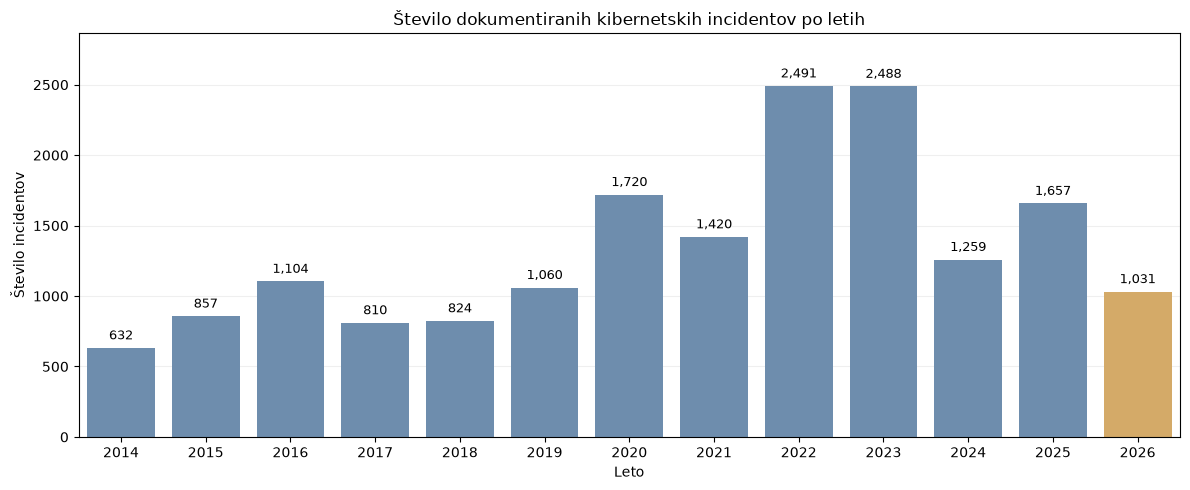

In [69]:
# Število incidentov po letih
yearly = df_viz["year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))

# Zadnje, nepopolno leto označimo posebej
colors = [
    "#648db7" if year < 2026 else "#e6ae56"
    for year in yearly.index
]

sns.barplot(
    x=yearly.index,
    y=yearly.values,
    hue=yearly.index,
    palette=colors,
    legend=False,
    ax=ax
)

# Število incidentov nad posameznim stolpcem
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:,.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title("Število dokumentiranih kibernetskih incidentov po letih")
ax.set_xlabel("Leto")
ax.set_ylabel("Število incidentov")
ax.set_ylim(0, yearly.max() * 1.15)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


* Največ incidentov je bilo dokumentiranih leta 2022 (2.491) in 2023 (2.488).

* Leta 2024 je število upadlo na 1.259, kar je skoraj 50 % manj kot leto prej.

* Leta 2025 je ponovno naraslo na 1.657.

* Leta 2026 je do konca avgusta zabeleženih 1.031 incidentov.


#### Mesečna porazdelitev incidentov

Analiziramo delež incidentov po mesecih znotraj posameznega leta. Normalizacija omogoča primerjavo mesečne porazdelitve med leti z različnim številom dokumentiranih incidentov.


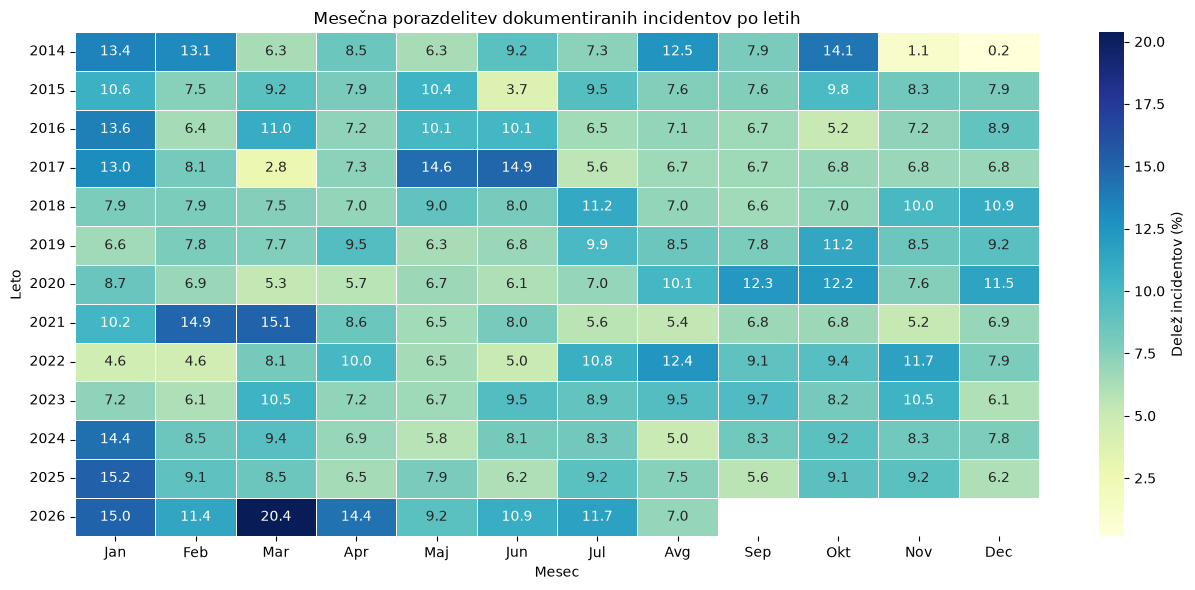

In [70]:

# Število incidentov po letih in mesecih
monthly_counts = pd.crosstab(df_viz["year"], df_viz["month"])

# Delež posameznega meseca v okviru istega leta
monthly_pct = monthly_counts.div(
    monthly_counts.sum(axis=1), axis=0
) * 100

# Označimo mesece, ki niso vključeni v zbirko za leto 2026
monthly_pct = monthly_pct.reindex(columns=range(1, 13))
monthly_pct.loc[2026, 9:12] = float("nan")

fig, ax = plt.subplots(figsize=(13, 6))

sns.heatmap(
    monthly_pct,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Delež incidentov (%)"},
    ax=ax
)

ax.set_title("Mesečna porazdelitev dokumentiranih incidentov po letih")
ax.set_xlabel("Mesec")
ax.set_ylabel("Leto")
ax.set_xticklabels(
    ["Jan", "Feb", "Mar", "Apr", "Maj", "Jun",
     "Jul", "Avg", "Sep", "Okt", "Nov", "Dec"]
)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()



### 5.2 Geografska pokritost

Preučimo geografsko porazdelitev javno dokumentiranih incidentov glede na državo prizadetega subjekta. Analiziramo zastopanost držav, koncentracijo incidentov in omejitve geografske pokritosti podatkovne zbirke.

#### 5.2.1 Porazdelitev incidentov po državah

Primerjamo države z največ dokumentiranimi incidenti. Neznane države obravnavamo ločeno, saj ne predstavljajo geografske kategorije.


In [71]:
# Za geografsko primerjavo uporabimo zapise z določeno kodo ISO3
geo_data = df_viz[df_viz["country_iso3"].notna()].copy()

# Število incidentov po državah
country_counts = (
    geo_data.groupby(["country_iso3", "country"])
    .size()
    .reset_index(name="stevilo_incidentov")
    .sort_values("stevilo_incidentov", ascending=False)
)

print("Vseh incidentov:", len(df_viz))
print("Incidentov z določeno kodo ISO3:", len(geo_data))
print("Incidentov brez kode ISO3:", len(df_viz) - len(geo_data))
print("Različnih kod držav:", country_counts["country_iso3"].nunique())

display(country_counts.head(15))



Vseh incidentov: 17353
Incidentov z določeno kodo ISO3: 16702
Incidentov brez kode ISO3: 651
Različnih kod držav: 170


,country_iso3,country,stevilo_incidentov
159,USA,United States of America,8213
51,GBR,United Kingdom of Great Britain and Northern I...,873
130,RUS,Russian Federation,506
72,ITA,Italy,473
157,UKR,Ukraine,445
24,CAN,Canada,434
66,IND,India,391
49,FRA,France,343
8,AUS,Australia,331
37,DEU,Germany,292


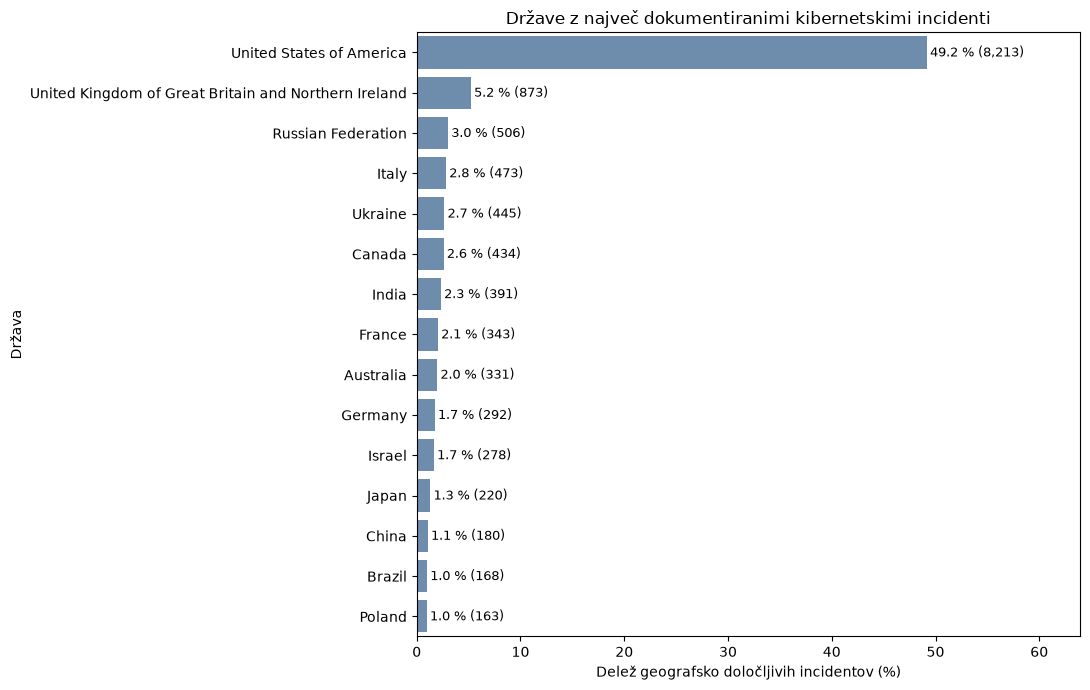

In [72]:
top15 = country_counts.head(15).copy()

# Delež glede na vse geografsko določljive incidente
top15["delez"] = (
    top15["stevilo_incidentov"] / len(geo_data) * 100
)

fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=top15,
    x="delez",
    y="country",
    color="#648db7",
    ax=ax
)

# Odstotek in število incidentov na koncu stolpcev
for bar, n, pct in zip(
    ax.patches,
    top15["stevilo_incidentov"],
    top15["delez"]
):
    ax.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f} % ({n:,})",
        va="center",
        fontsize=9
    )

ax.set_xlim(0, top15["delez"].max() * 1.3)
ax.set_title("Države z največ dokumentiranimi kibernetskimi incidenti")
ax.set_xlabel("Delež geografsko določljivih incidentov (%)")
ax.set_ylabel("Država")

plt.tight_layout()
plt.show()



Geografska porazdelitev incidentov je izrazito neenakomerna. ZDA predstavljajo 49,2 % vseh geografsko določljivih incidentov, medtem ko posamezne druge države prispevajo bistveno manjše deleže. Zbirka vključuje 170 različnih državnih kod, pri 3,8 % zapisov pa koda države ni določena. Zaradi izrazite koncentracije zapisov in možnih razlik v poročanju števila dokumentiranih incidentov ni mogoče neposredno enačiti z dejansko stopnjo kibernetske ogroženosti držav.


#### 5.2.2 Koncentracija incidentov med državami

Preverimo, kolikšen delež dokumentiranih incidentov je skoncentriran v državah z največ zapisi. Kumulativna porazdelitev omogoča oceno geografske neenakomernosti podatkovne zbirke.


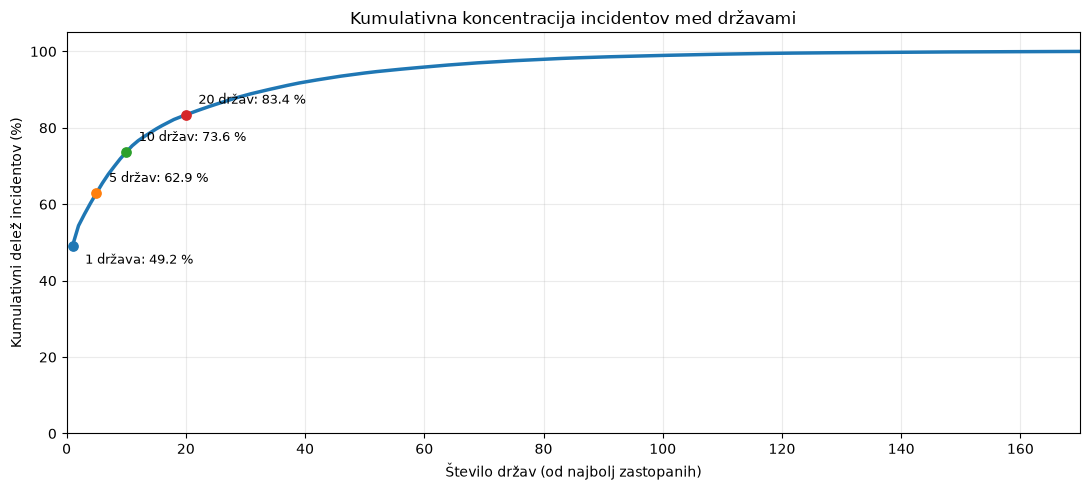

In [73]:

# Države razvrstimo po številu incidentov
concentration = country_counts.sort_values(
    "stevilo_incidentov", ascending=False
).reset_index(drop=True)

# Kumulativni delež incidentov
concentration["kumulativni_delez"] = (
    concentration["stevilo_incidentov"].cumsum()
    / concentration["stevilo_incidentov"].sum() * 100
)

fig, ax = plt.subplots(figsize=(11, 5))

sns.lineplot(
    x=range(1, len(concentration) + 1),
    y=concentration["kumulativni_delez"],
    marker=None,
    linewidth=2.5,
    ax=ax
)

# Označimo koncentracijo v prvih 1, 5, 10 in 20 državah
for n in [1, 5, 10, 20]:
    pct = concentration.loc[n - 1, "kumulativni_delez"]
    ax.scatter(n, pct, s=45, zorder=3)
    ax.annotate(
        f"{n} država: {pct:.1f} %" if n == 1    
        else
            f"{n} držav: {pct:.1f} %",
        (n, pct),
        xytext=(9, -13 if n == 1 else 8),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title("Kumulativna koncentracija incidentov med državami")
ax.set_xlabel("Število držav (od najbolj zastopanih)")
ax.set_ylabel("Kumulativni delež incidentov (%)")
ax.set_xlim(0, len(concentration))
ax.set_ylim(0, 105)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()



Geografska koncentracija dokumentiranih incidentov je izrazita: deset najbolj zastopanih držav zajema 73,6 % vseh incidentov z določeno državo, medtem ko preostalih 160 držav predstavlja le 26,4 %. Takšna neenakomerna pokritost lahko vpliva na primerjave med državami, zato je pri nadaljnji analizi treba upoštevati velikost vzorca in uporabljati deleže znotraj posameznih držav.



#### 5.2.3 Svetovna geografska pokritost

Geografsko porazdelitev dokumentiranih incidentov prikažemo na svetovnem zemljevidu. Zaradi velikih razlik med državami uporabimo logaritemsko barvno lestvico, ki omogoča preglednejšo primerjavo držav z manjšim številom incidentov.


In [74]:
# Logaritemska lestvica za preglednejši prikaz
map_data = country_counts.copy()
map_data["log_incidentov"] = (
    map_data["stevilo_incidentov"].apply(lambda n: __import__("math").log10(n))
)

fig = px.choropleth(
    map_data,
    locations="country_iso3",
    locationmode="ISO-3",
    color="log_incidentov",
    hover_name="country",
    hover_data={
        "country_iso3": True,
        "stevilo_incidentov": True,
        "log_incidentov": False
    },
    color_continuous_scale="YlGnBu",
    labels={"log_incidentov": "Število incidentov (log₁₀)"},
    title="Geografska porazdelitev dokumentiranih incidentov"
)

fig.update_geos(
    showcoastlines=True,
    showcountries=True,
    projection_type="natural earth"
)

fig.update_layout(height=550, margin=dict(l=0, r=0, t=55, b=0))
fig.show()



### 5.3 Spreminjanje geografske porazdelitve skozi čas

Primerjamo deleže dokumentiranih incidentov po državah znotraj posameznega leta. Prikažemo deset najbolj zastopanih držav v celotnem obdobju, druge pa združimo v kategorijo »Ostale države«. S tem preverimo, kako se geografska sestava zbirke spreminja skozi čas.


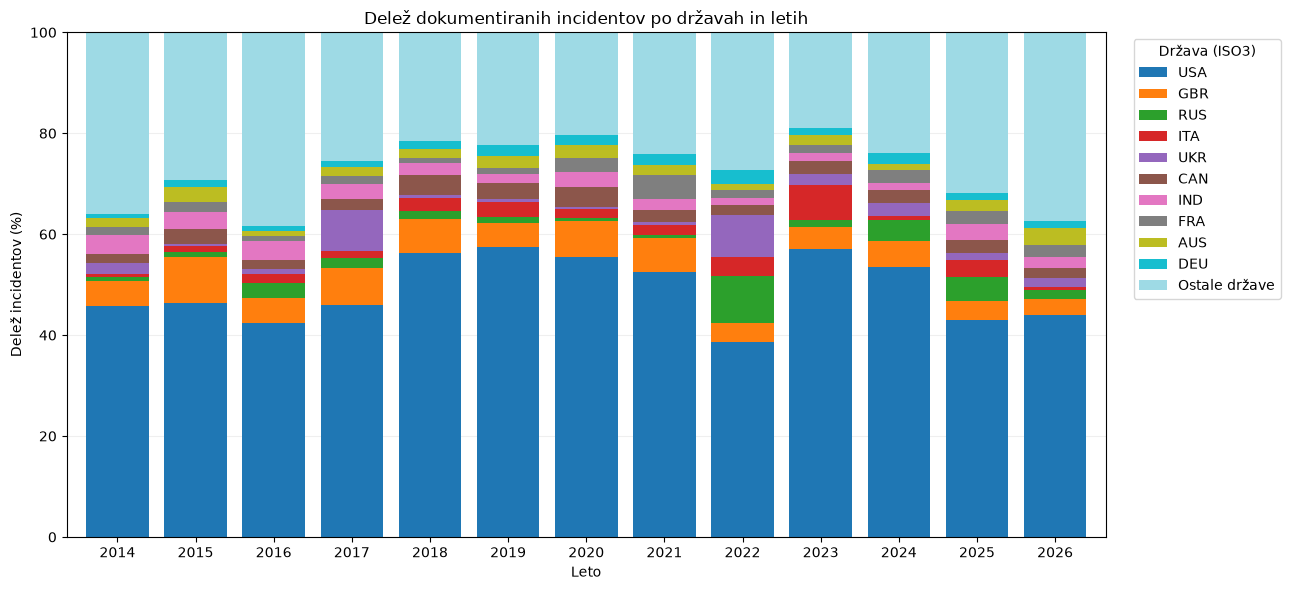

In [75]:
# Deset najbolj zastopanih držav skozi celotno obdobje
top_codes = country_counts.head(10)["country_iso3"].tolist()

# Za vsako leto določimo državo oziroma skupino Ostale države
year_country = geo_data[["year", "country_iso3"]].copy()
year_country["skupina"] = year_country["country_iso3"].where(
    year_country["country_iso3"].isin(top_codes),
    "Ostale države"
)

# Delež vsake skupine znotraj leta
yearly_shares = pd.crosstab(
    year_country["year"], year_country["skupina"],
    normalize="index"
) * 100

# Enak vrstni red držav v vseh letih
yearly_shares = yearly_shares.reindex(
    columns=top_codes + ["Ostale države"], fill_value=0
)

fig, ax = plt.subplots(figsize=(13, 6))

yearly_shares.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    colormap="tab20",
    width=0.8
)

ax.set_title("Delež dokumentiranih incidentov po državah in letih")
ax.set_xlabel("Leto")
ax.set_ylabel("Delež incidentov (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Država (ISO3)", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### 5.4 Omejitve časovne in geografske pokritosti

Pri primerjavi držav in let upoštevamo neenakomerno zastopanost incidentov, različno velikost vzorcev ter možnost sprememb v načinu zbiranja podatkov. Preverimo, koliko držav ima dovolj dokumentiranih incidentov za nadaljnjo primerjalno analizo.


In [76]:
# Število incidentov za posamezno državo
country_sizes = geo_data.groupby("country_iso3").size()

# Pregled velikosti vzorcev
thresholds = [1, 10, 30, 50, 100, 200]

coverage_summary = pd.DataFrame({
    "Najmanj incidentov": thresholds,
    "Število držav": [
        (country_sizes >= n).sum() for n in thresholds
    ],
    "Delež incidentov (%)": [
        country_sizes[country_sizes >= n].sum()
        / len(geo_data) * 100
        for n in thresholds
    ]
})

display(coverage_summary.round(2))


,Najmanj incidentov,Število držav,Delež incidentov (%)
0,1,170,100.00
1,10,85,98.29
2,30,51,94.55
3,50,39,91.74
4,100,20,83.41
5,200,12,76.63



Geografska pokritost zbirke je izrazito neenakomerna. Od 170 državnih kod jih ima 85 manj kot 10 dokumentiranih incidentov, medtem ko 20 najbolj zastopanih držav zajema 83,41 % vseh geografsko določljivih zapisov. Za nadaljnje primerjave bo zato treba upoštevati velikost vzorcev, posebej pri analizah po državah in letih. V tej fazi držav ne izključujemo, temveč bomo ustrezne pragove določili glede na posamezno raziskovalno metodo.



## 6. Značilnosti kibernetskih incidentov

Analiziramo spremembe v vrstah in podvrstah dokumentiranih incidentov, njihovo povezanost s ciljnimi sektorji ter razlike med državami in časovnimi obdobji.

### 6.1 Vrste incidentov skozi čas

Primerjamo deleže posameznih vrst incidentov med leti. Z normalizacijo znotraj posameznega leta preverimo, kako se spreminja sestava dokumentiranih kibernetskih incidentov, neodvisno od skupnega števila zapisov.


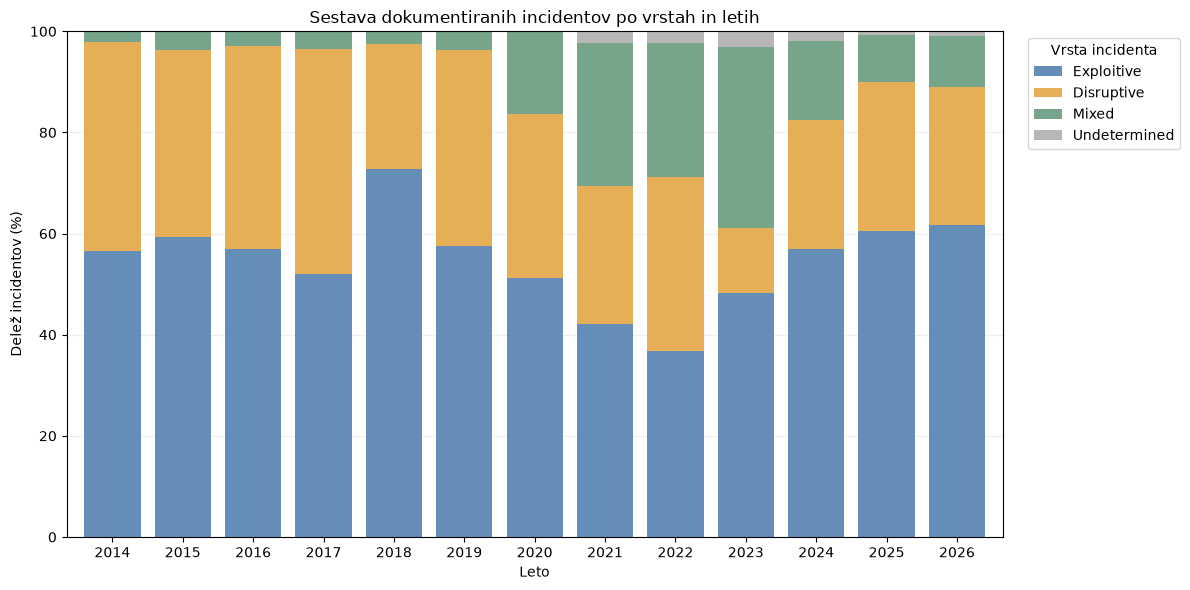

In [77]:
# Delež posamezne vrste incidenta znotraj leta
event_type_yearly = pd.crosstab(
    df_viz["year"],
    df_viz["event_type"],
    normalize="index"
) * 100

# Dosleden vrstni red kategorij
event_type_yearly = event_type_yearly.reindex(
    columns=["Exploitive", "Disruptive", "Mixed", "Undetermined"],
    fill_value=0
)

fig, ax = plt.subplots(figsize=(12, 6))

event_type_yearly.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=["#648db7", "#e6ae56", "#77a58a", "#b7b7b7"],
    width=0.8
)

ax.set_title("Sestava dokumentiranih incidentov po vrstah in letih")
ax.set_xlabel("Leto")
ax.set_ylabel("Delež incidentov (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Vrsta incidenta", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



### 6.2 Podvrste incidentov skozi čas

Analiziramo spreminjanje zastopanosti posameznih podvrst kibernetskih incidentov med leti. Deleže izračunamo glede na število incidentov v posameznem letu, pri čemer lahko en incident pripada več podvrstam.


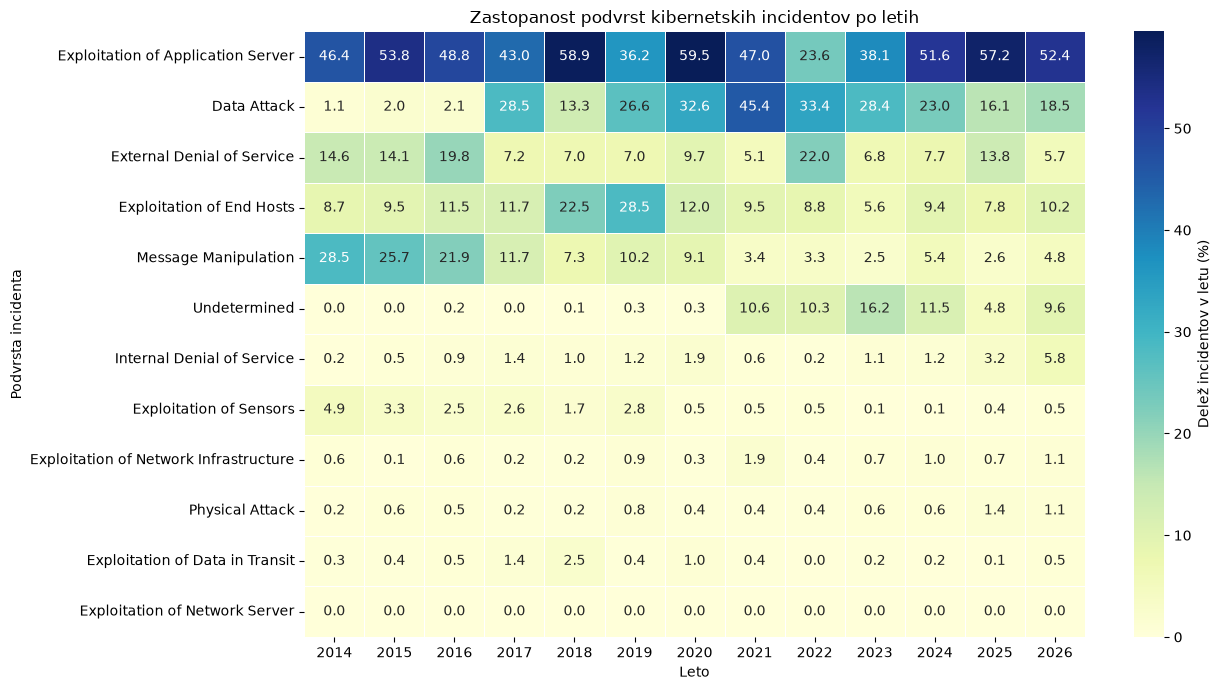

In [78]:
# Podvrstam dodamo leto pripadajočega incidenta
subtype_year = df_subtypes_viz.merge(
    df_viz[["slug", "year"]],
    on="slug",
    validate="many_to_one"
)

# Število incidentov po podvrstah in letih
subtype_counts = pd.crosstab(
    subtype_year["event_subtype"],
    subtype_year["year"]
)

# Število vseh incidentov v posameznem letu
year_totals = df_viz.groupby("year").size()

# Delež incidentov, pri katerih se pojavi posamezna podvrsta
subtype_pct = subtype_counts.div(year_totals, axis=1) * 100

# Podvrste razvrstimo po skupni pogostosti
subtype_order = (
    df_subtypes_viz["event_subtype"]
    .value_counts()
    .index
)
subtype_pct = subtype_pct.reindex(subtype_order)

fig, ax = plt.subplots(figsize=(13, 7))

sns.heatmap(
    subtype_pct,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.4,
    cbar_kws={"label": "Delež incidentov v letu (%)"},
    ax=ax
)

ax.set_title("Zastopanost podvrst kibernetskih incidentov po letih")
ax.set_xlabel("Leto")
ax.set_ylabel("Podvrsta incidenta")

plt.tight_layout()
plt.show()


### 6.3 Ciljni sektorji skozi čas

Analiziramo spreminjanje zastopanosti gospodarskih sektorjev med žrtvami javno dokumentiranih kibernetskih incidentov. Deleže računamo glede na vse incidente v posameznem letu, pri čemer nedoločen sektor ohranimo kot ločeno kategorijo.


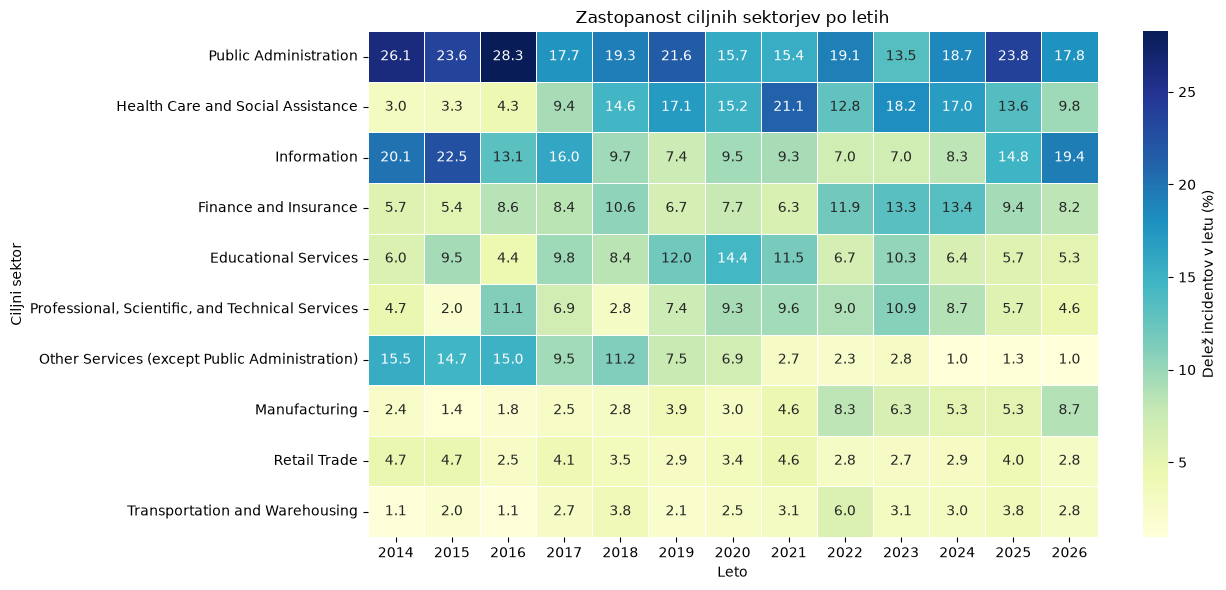

In [79]:
# Število incidentov po sektorjih in letih
sector_counts = pd.crosstab(
    df_viz["industry"],
    df_viz["year"]
)

# Deleži sektorjev v posameznem letu
sector_pct = sector_counts.div(
    sector_counts.sum(axis=0), axis=1
) * 100

# Deset najpogostejših sektorjev v celotni zbirki
top_sectors = df_viz["industry"].value_counts().head(10).index
sector_pct = sector_pct.loc[top_sectors]

fig, ax = plt.subplots(figsize=(13, 6))

sns.heatmap(
    sector_pct,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.4,
    cbar_kws={"label": "Delež incidentov v letu (%)"},
    ax=ax
)

ax.set_title("Zastopanost ciljnih sektorjev po letih")
ax.set_xlabel("Leto")
ax.set_ylabel("Ciljni sektor")

plt.tight_layout()
plt.show()


### 6.4 Povezava med ciljnimi sektorji in vrstami incidentov

Primerjamo porazdelitev vrst kibernetskih incidentov med ciljnimi sektorji. Deleže izračunamo znotraj vsakega sektorja, da ugotovimo, ali se profili dokumentiranih incidentov med gospodarskimi dejavnostmi razlikujejo.


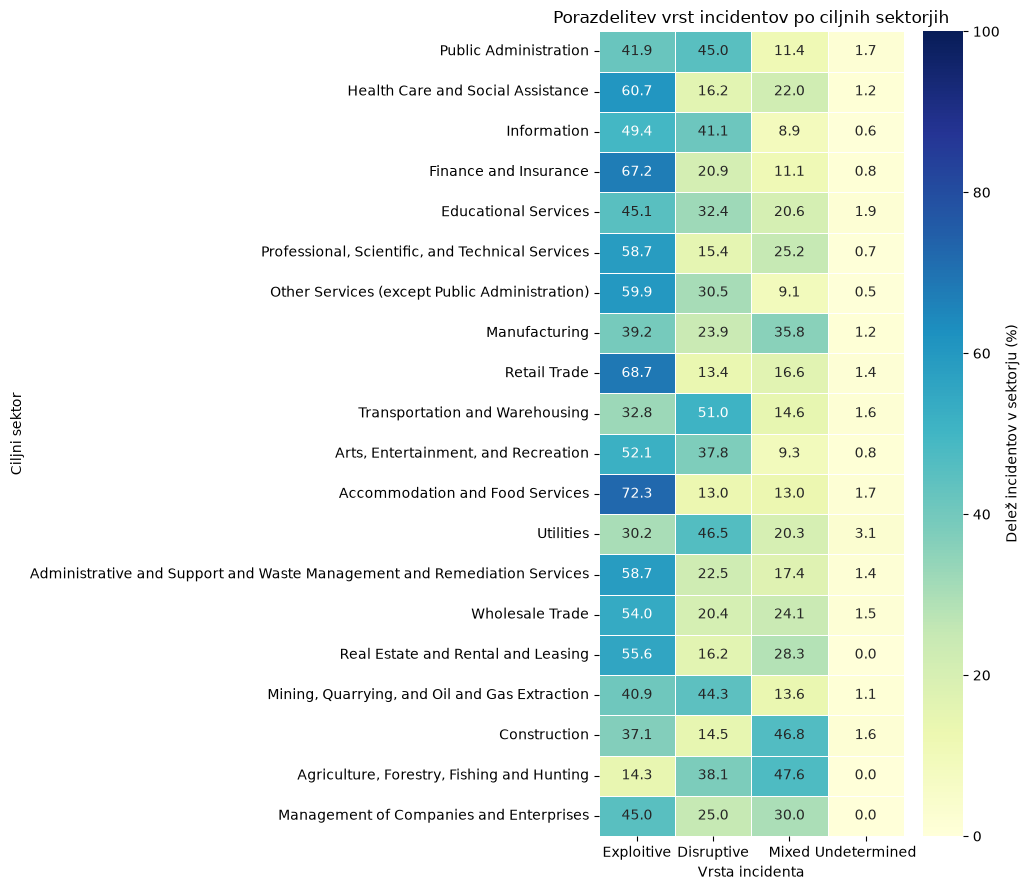

In [80]:
# Izločimo nedoločen sektor
sector_data = df_viz[df_viz["industry"] != "Undetermined"]

# Število incidentov po sektorjih in vrstah
sector_type_counts = pd.crosstab(
    sector_data["industry"],
    sector_data["event_type"]
)

# Deleži vrst incidentov znotraj vsakega sektorja
sector_type_pct = (
    sector_type_counts.div(sector_type_counts.sum(axis=1), axis=0) * 100
)

# Sektorje razvrstimo po številu incidentov
sector_order = sector_type_counts.sum(axis=1).sort_values(
    ascending=False
).index

sector_type_pct = sector_type_pct.reindex(
    index=sector_order,
    columns=["Exploitive", "Disruptive", "Mixed", "Undetermined"],
    fill_value=0
)

fig, ax = plt.subplots(figsize=(10, 9))

sns.heatmap(
    sector_type_pct,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.4,
    cbar_kws={"label": "Delež incidentov v sektorju (%)"},
    ax=ax
)

ax.set_title("Porazdelitev vrst incidentov po ciljnih sektorjih")
ax.set_xlabel("Vrsta incidenta")
ax.set_ylabel("Ciljni sektor")

plt.tight_layout()
plt.show()


Porazdelitev vrst dokumentiranih incidentov se med ciljnimi sektorji razlikuje. V zdravstvu in finančnih dejavnostih prevladujejo izkoriščevalni incidenti, medtem ko imajo javna uprava, promet in energetika večji delež motilnih incidentov. V proizvodnji je opazen tudi visok delež mešanih incidentov. Pri interpretaciji je treba upoštevati velikost vzorcev in morebitne razlike med državami ter časovnimi obdobji.



### 6.5 Motivi in vrste napadalcev

Primerjamo zastopanost motivov glede na vrsto napadalca. Deleže izračunamo znotraj posamezne vrste napadalca, pri čemer upoštevamo tudi nedoločene motive in velikost posameznih skupin.


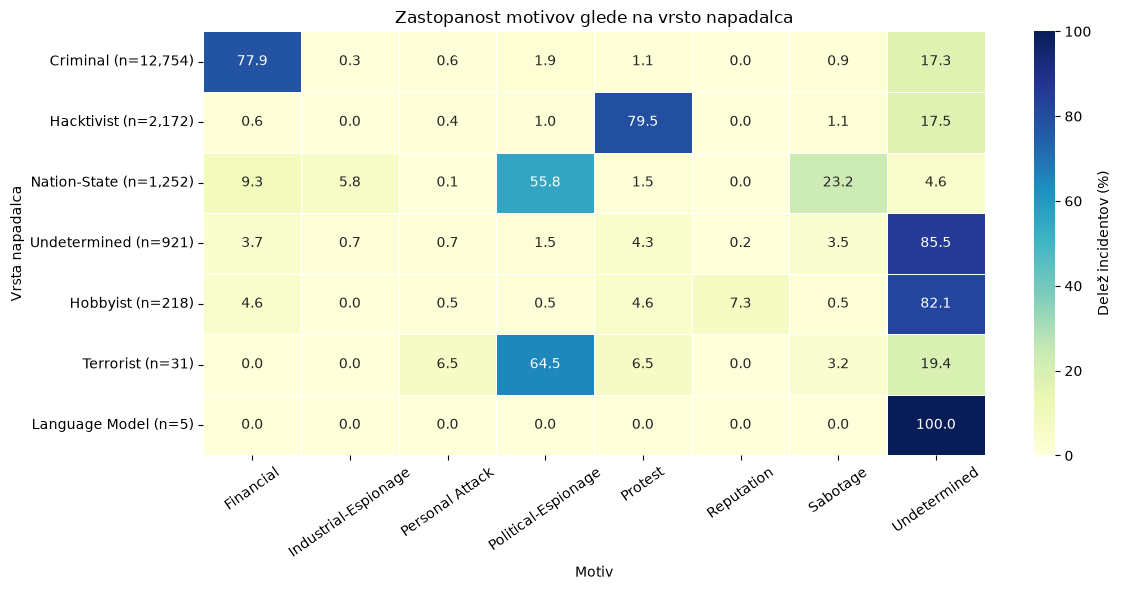

In [81]:
# Motive povežemo z vrstami napadalcev
actor_motives = df_motives_viz.merge(
    df_viz[["slug", "actor_type"]],
    on="slug",
    validate="many_to_one"
)

# Število incidentov po vrsti napadalca
actor_sizes = df_viz["actor_type"].value_counts()

# Število posameznih motivov
motive_counts = pd.crosstab(
    actor_motives["actor_type"],
    actor_motives["motive"]
)

# Deleži glede na število incidentov posamezne vrste napadalca
motive_pct = motive_counts.div(actor_sizes, axis=0) * 100

# Razvrstimo glede na velikost skupin
motive_pct = motive_pct.loc[actor_sizes.index]


# Zagotovimo numerični tip podatkov za Seaborn
motive_pct = motive_pct.astype("float64")



fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    motive_pct,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.4,
    cbar_kws={"label": "Delež incidentov (%)"},
    ax=ax
)

ax.set_yticklabels(
    [f"{actor} (n={actor_sizes[actor]:,})" for actor in motive_pct.index],
    rotation=0
)
ax.set_title("Zastopanost motivov glede na vrsto napadalca")
ax.set_xlabel("Motiv")
ax.set_ylabel("Vrsta napadalca")
ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()



### 6.6 Primerjava profilov kibernetskih incidentov med državami

Preverimo, ali se sestava dokumentiranih incidentov razlikuje med državami glede na vrste napadov, njihove podvrste in ciljne sektorje. Ugotovitve bodo osnova za oblikovanje raziskovalnih vprašanj ter izbiro dodatnih gospodarskih, digitalnih in varnostnih kazalnikov.


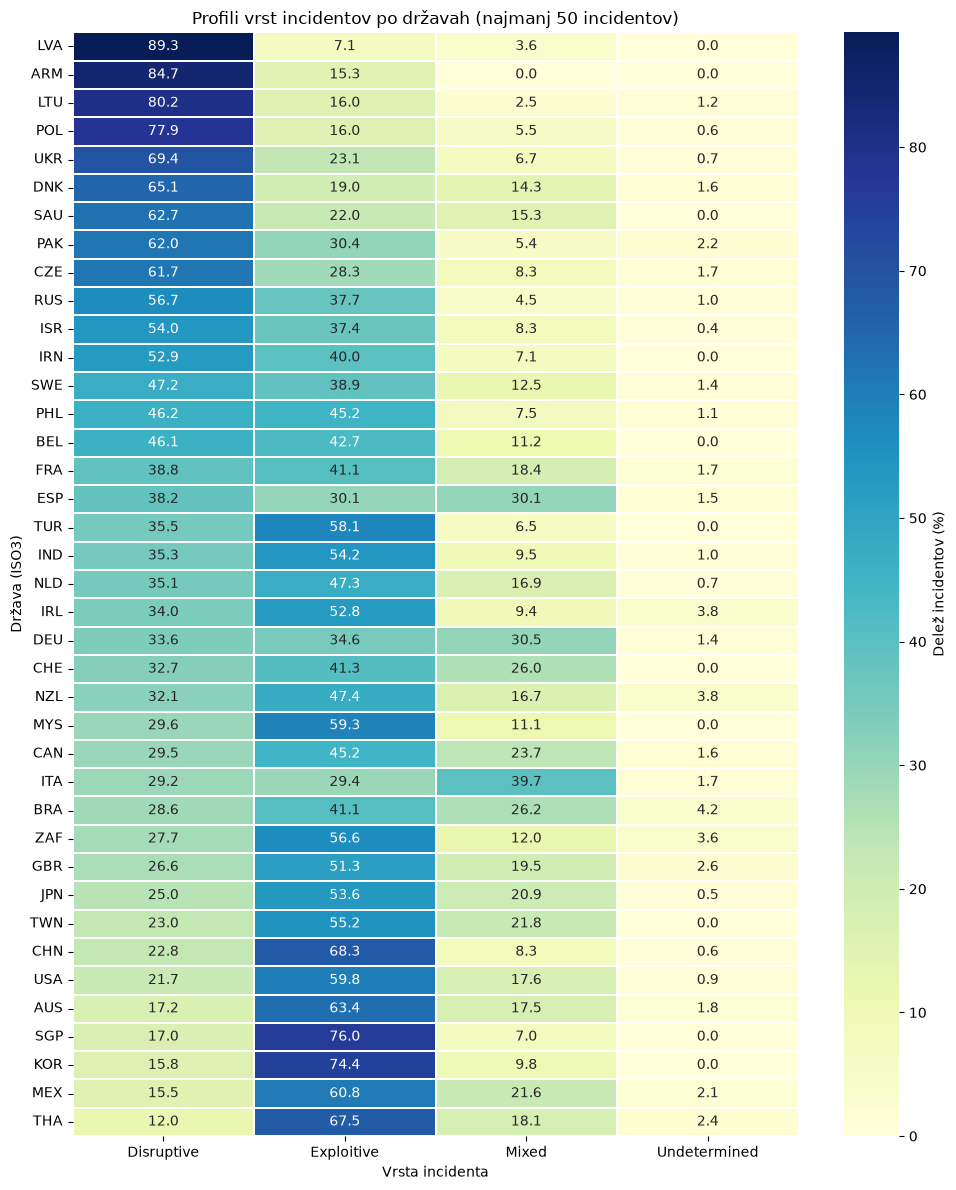

In [82]:

# Za začetno primerjavo izberemo države z vsaj 50 incidenti
country_sizes = geo_data["country_iso3"].value_counts()
selected_codes = country_sizes[country_sizes >= 50].index

comparison_data = geo_data[
    geo_data["country_iso3"].isin(selected_codes)
]

# Deleži vrst incidentov znotraj vsake države
country_profiles = pd.crosstab(
    comparison_data["country_iso3"],
    comparison_data["event_type"],
    normalize="index"
) * 100

# Države razvrstimo po deležu motilnih incidentov
country_profiles = (
    country_profiles.astype(float)
    .sort_values("Disruptive", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 12))

sns.heatmap(
    country_profiles,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.3,
    cbar_kws={"label": "Delež incidentov (%)"},
    ax=ax
)

ax.set_title("Profili vrst incidentov po državah (najmanj 50 incidentov)")
ax.set_xlabel("Vrsta incidenta")
ax.set_ylabel("Država (ISO3)")

plt.tight_layout()
plt.show()



#### 6.6.1 Podvrste incidentov po državah

Primerjamo zastopanost posameznih podvrst kibernetskih incidentov med državami z najmanj 50 dokumentiranimi incidenti. Deleže izračunamo glede na število incidentov znotraj posamezne države, pri čemer lahko posamezen incident pripada več podvrstam.


*Ali razlike v glavnih vrstah incidentov med državami izhajajo iz različnih podvrst napadov ali iz različne sestave ciljnih sektorjev?*

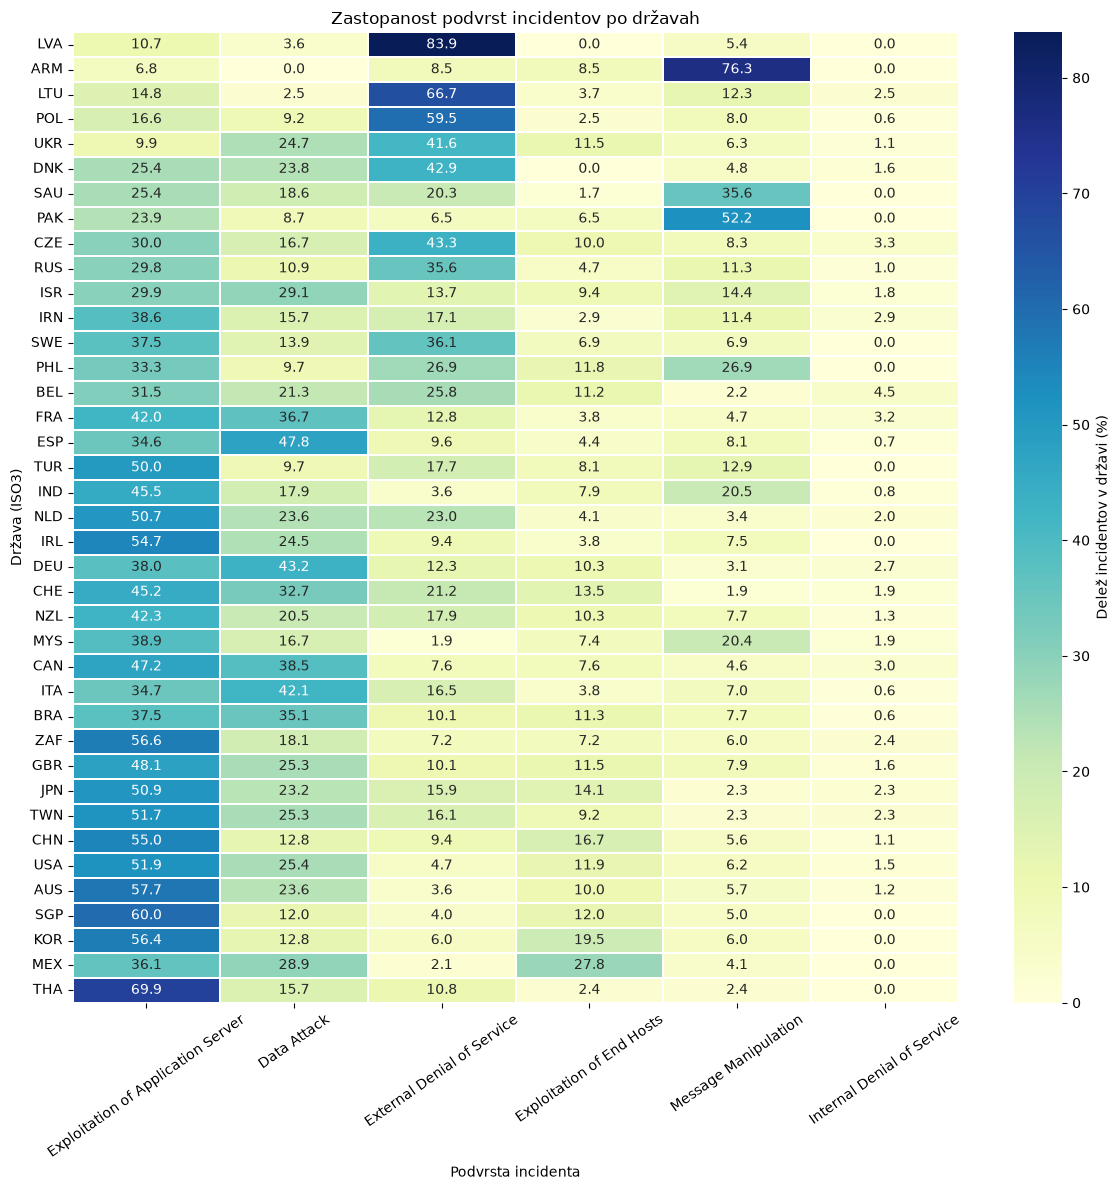

In [83]:

# Podvrste povežemo z državami
country_subtypes = df_subtypes_viz.merge(
    comparison_data[["slug", "country_iso3"]],
    on="slug",
    how="inner",
    validate="many_to_one"
)

# Število incidentov po podvrstah in državah
subtype_country_counts = pd.crosstab(
    country_subtypes["country_iso3"],
    country_subtypes["event_subtype"]
)

# Deleži glede na število incidentov posamezne države
country_totals = comparison_data["country_iso3"].value_counts()

subtype_country_pct = (
    subtype_country_counts.div(country_totals, axis=0) * 100
)

# Izberemo šest najpogostejših določenih podvrst
top_subtypes = (
    df_subtypes_viz.loc[
        df_subtypes_viz["event_subtype"] != "Undetermined",
        "event_subtype"
    ]
    .value_counts()
    .head(6)
    .index
)

# Ohranimo vrstni red držav s prejšnjega grafa
subtype_country_pct = subtype_country_pct.reindex(
    index=country_profiles.index,
    columns=top_subtypes,
    fill_value=0
).astype(float)

fig, ax = plt.subplots(figsize=(12, 12))

sns.heatmap(
    subtype_country_pct,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.3,
    cbar_kws={"label": "Delež incidentov v državi (%)"},
    ax=ax
)

ax.set_title("Zastopanost podvrst incidentov po državah")
ax.set_xlabel("Podvrsta incidenta")
ax.set_ylabel("Država (ISO3)")
ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


**Pomembno:** za posamezno državo se deleži podvrst lahko seštejejo nad 100 %, saj lahko incident pripada več podvrstam.


#### 6.6.2 Ciljni sektorji po državah

Primerjamo zastopanost ciljnih gospodarskih sektorjev med državami. Deleže izračunamo znotraj posamezne države, da ugotovimo, ali se nacionalni profili dokumentiranih incidentov razlikujejo tudi glede na prizadete sektorje.


In [84]:

# Število incidentov po državah in ciljnih sektorjih
country_sector_counts = pd.crosstab(
    comparison_data["country_iso3"],
    comparison_data["industry"]
)

In [85]:
# Delež sektorjev znotraj posamezne države
country_sector_pct = (
    country_sector_counts.div(
        country_sector_counts.sum(axis=1), axis=0
    ) * 100
)

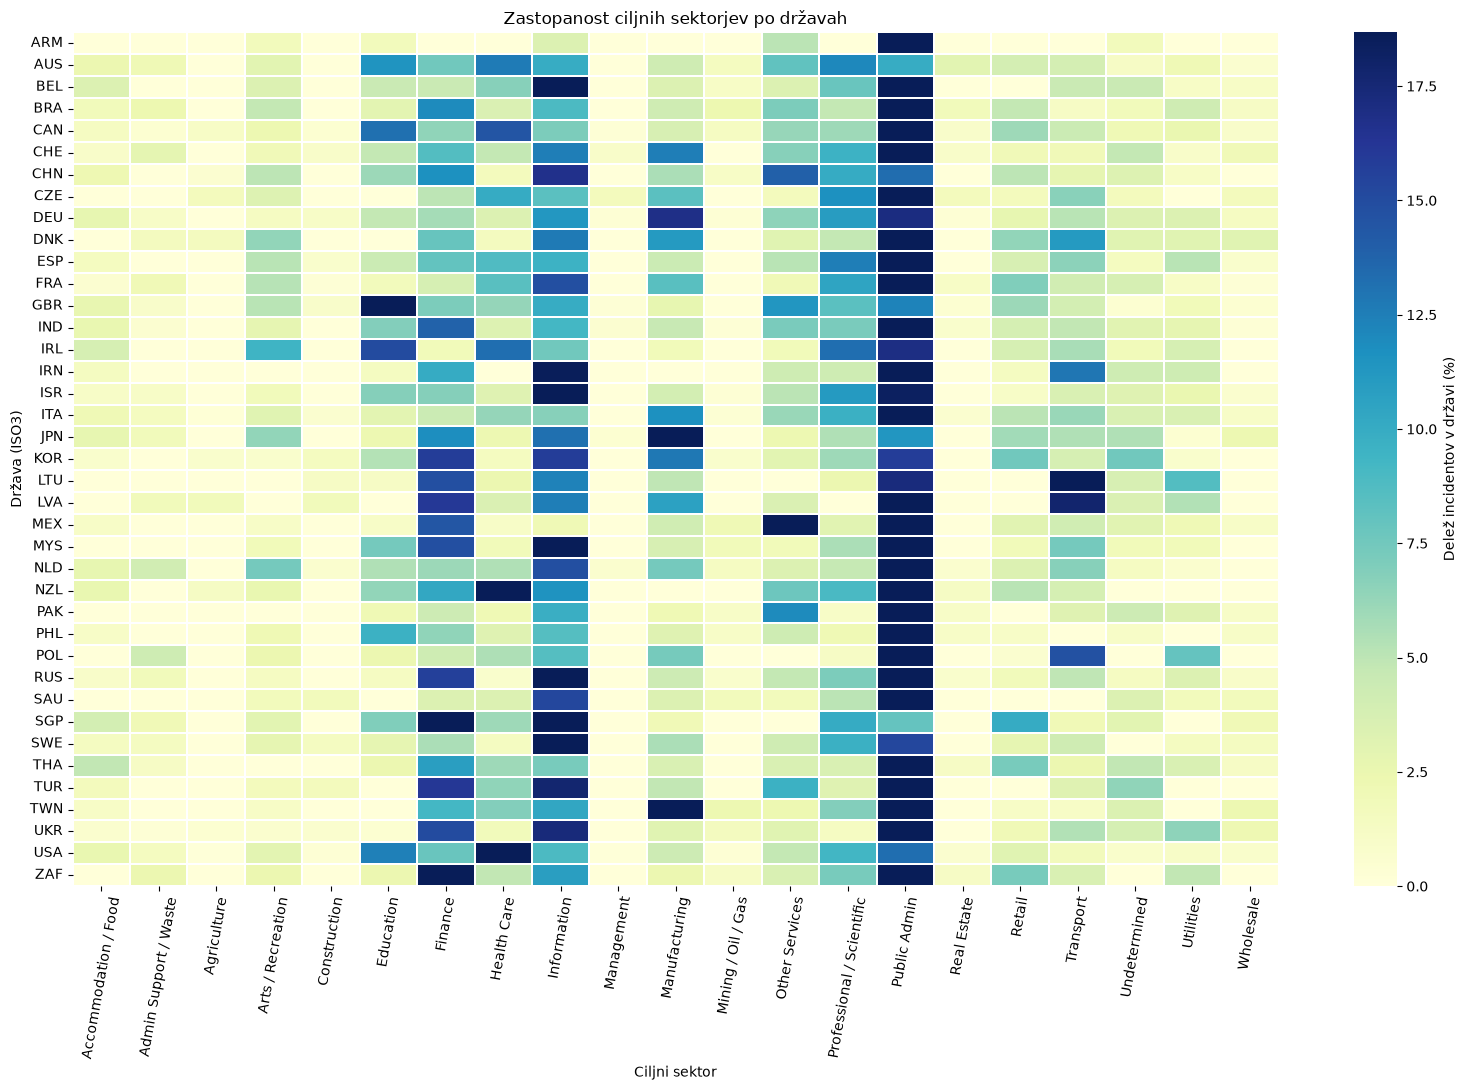

In [86]:
# Kopija tabele za prikaz
country_sector_plot = country_sector_pct.copy()

# Skrajšana imena sektorjev samo za ta graf
sector_short_names = {
    "Public Administration": "Public Admin",
    "Health Care and Social Assistance": "Health Care",
    "Information": "Information",
    "Finance and Insurance": "Finance",
    "Educational Services": "Education",
    "Professional, Scientific, and Technical Services": "Professional / Scientific",
    "Other Services (except Public Administration)": "Other Services",
    "Manufacturing": "Manufacturing",
    "Retail Trade": "Retail",
    "Transportation and Warehousing": "Transport",
    "Arts, Entertainment, and Recreation": "Arts / Recreation",
    "Accommodation and Food Services": "Accommodation / Food",
    "Utilities": "Utilities",
    "Administrative and Support and Waste Management and Remediation Services": "Admin Support / Waste",
    "Wholesale Trade": "Wholesale",
    "Real Estate and Rental and Leasing": "Real Estate",
    "Mining, Quarrying, and Oil and Gas Extraction": "Mining / Oil / Gas",
    "Construction": "Construction",
    "Agriculture, Forestry, Fishing and Hunting": "Agriculture",
    "Management of Companies and Enterprises": "Management",
    "Undetermined": "Undetermined"
}

country_sector_plot = country_sector_plot.rename(columns=sector_short_names)

# Barvna skala: omejimo zgornjo mejo na 95. percentil,
# da visoki ekstremi ne stisnejo vseh ostalih razlik
vmax_value = np.nanpercentile(country_sector_plot.to_numpy(), 95)

fig, ax = plt.subplots(figsize=(16, 11))

sns.heatmap(
    country_sector_plot,
    cmap="YlGnBu",
    linewidths=0.3,
    vmin=0,
    vmax=vmax_value,
    cbar_kws={"label": "Delež incidentov v državi (%)"},
    ax=ax
)

ax.set_title("Zastopanost ciljnih sektorjev po državah")
ax.set_xlabel("Ciljni sektor")
ax.set_ylabel("Država (ISO3)")
ax.tick_params(axis="x", rotation=80)

plt.tight_layout()
plt.show()


#### 6.6.3 Povezava med podvrstami incidentov in ciljnimi sektorji po državah

Preverimo, kako se zastopanost posameznih podvrst kibernetskih incidentov razlikuje med ciljnimi sektorji in državami. Osredotočimo se na izbrane države z izrazitimi profili, ugotovljenimi v predhodnih analizah.


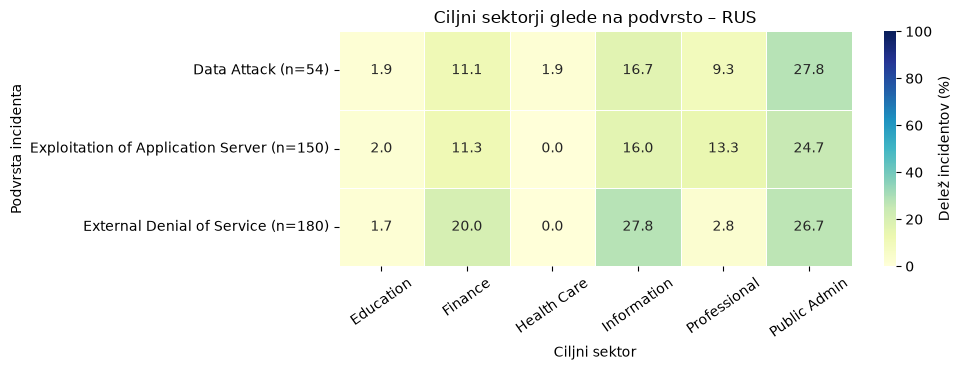

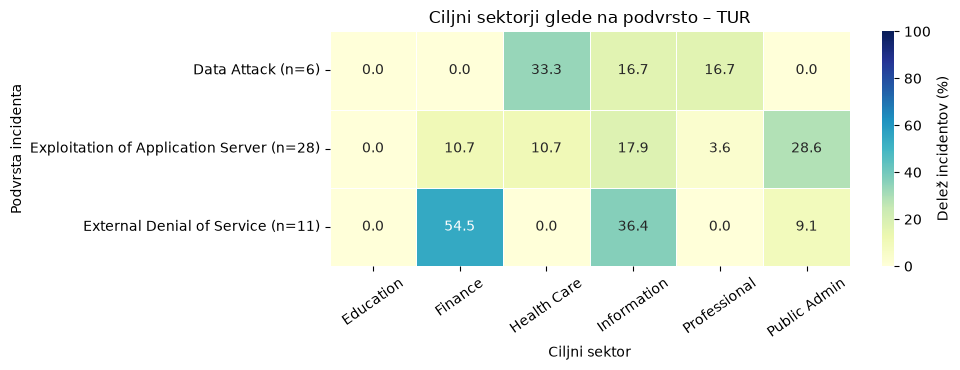

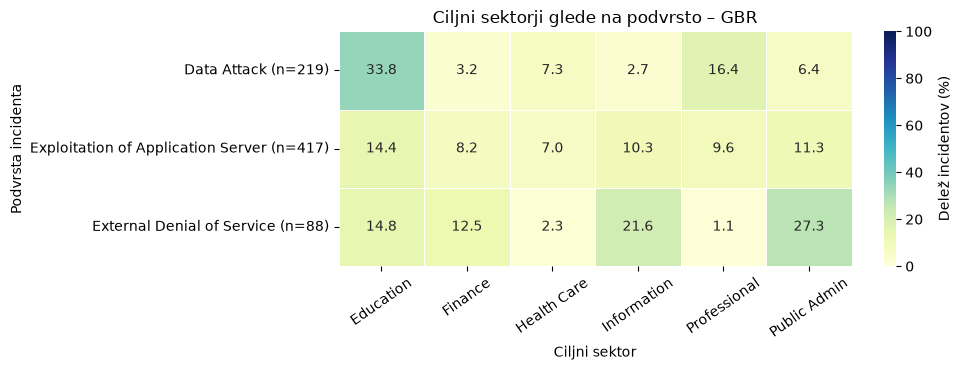

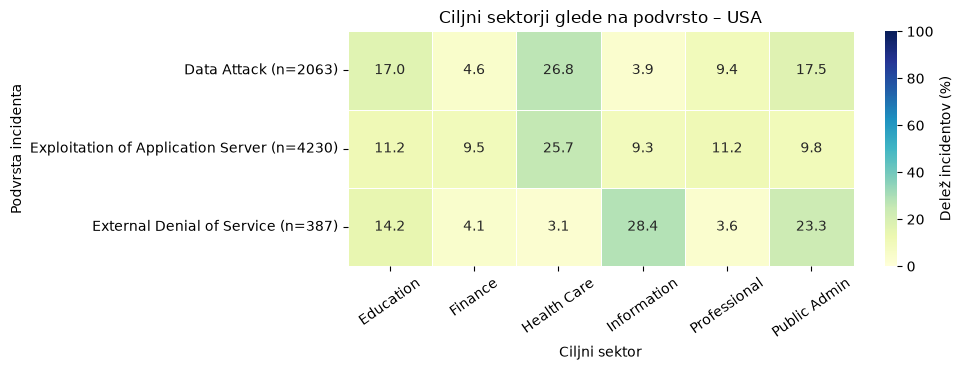

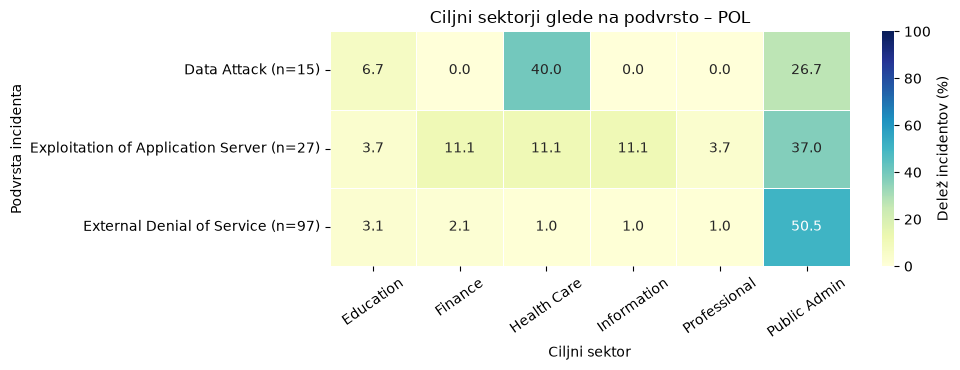

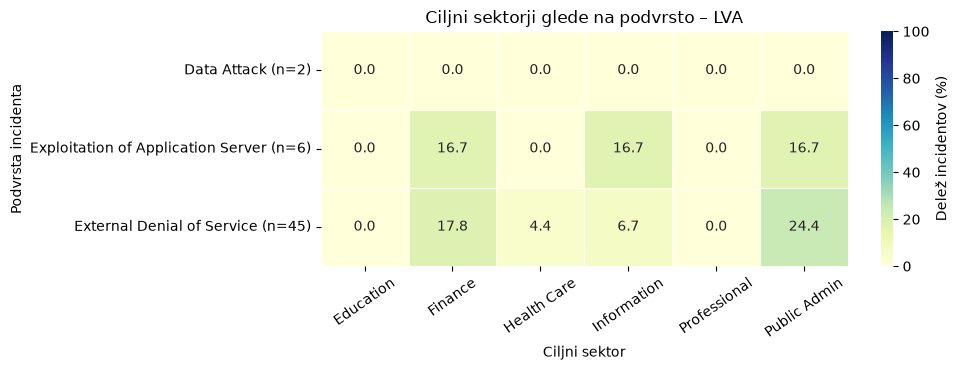

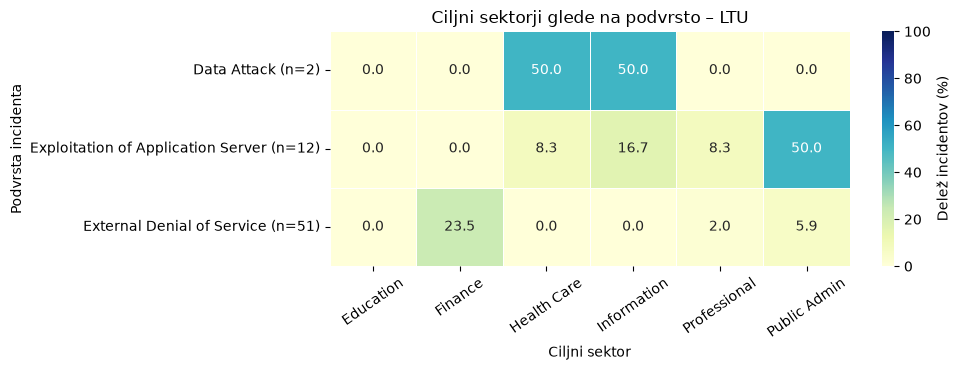

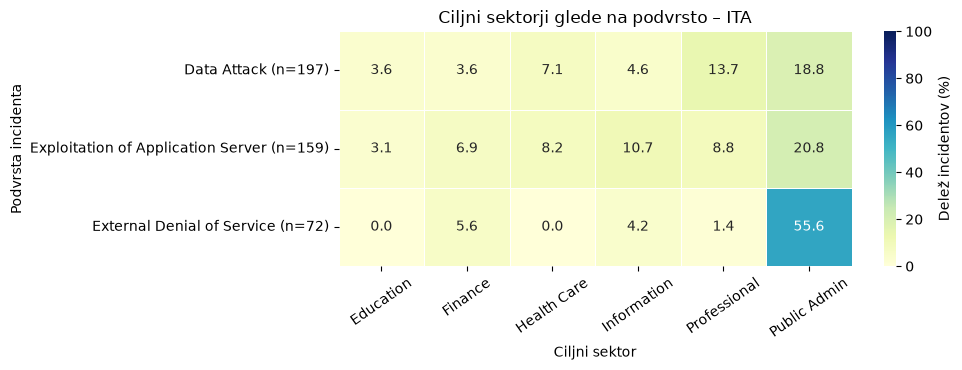

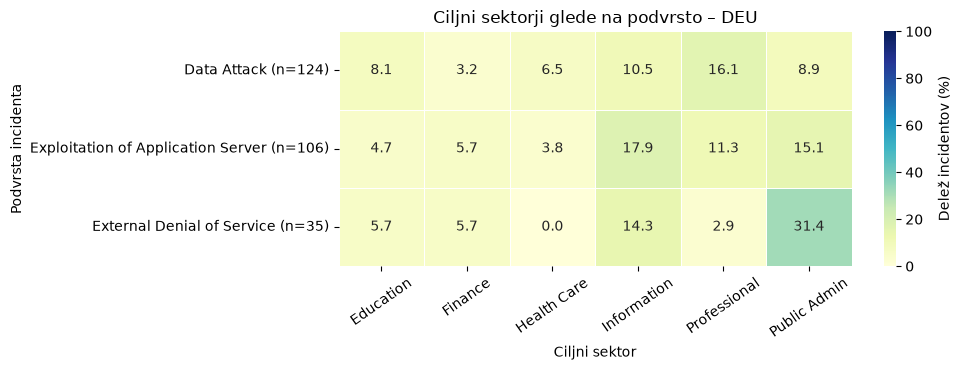

In [87]:

# Države in podvrste za primerjavo
selected_countries = [
    "RUS", "TUR", "GBR", "USA", "POL",
    "LVA", "LTU", "ITA", "DEU"
]

selected_subtypes = [
    "Data Attack",
    "Exploitation of Application Server",
    "External Denial of Service"
]

selected_sectors = [
    "Educational Services",
    "Finance and Insurance",
    "Health Care and Social Assistance",
    "Information",
    "Professional, Scientific, and Technical Services",
    "Public Administration"
]

short_names = {
    "Educational Services": "Education",
    "Finance and Insurance": "Finance",
    "Health Care and Social Assistance": "Health Care",
    "Information": "Information",
    "Professional, Scientific, and Technical Services": "Professional",
    "Public Administration": "Public Admin"
}

# Uporabimo povezovalno tabelo, ne kombiniranih nizov iz df_viz
data = df_subtypes_viz.merge(
    df_viz[["slug", "country_iso3", "industry"]],
    on="slug",
    validate="many_to_one"
)

data = data[
    data["country_iso3"].isin(selected_countries)
    & data["event_subtype"].isin(selected_subtypes)
    & (data["industry"] != "Undetermined")
]

# Imenovalec vključuje vse znane sektorje
totals = data.groupby(
    ["country_iso3", "event_subtype"]
)["slug"].nunique()

# Število incidentov po posameznem sektorju
counts = pd.crosstab(
    [data["country_iso3"], data["event_subtype"]],
    data["industry"]
)

# Deleži znotraj države in podvrste
percentages = counts.div(totals, axis=0) * 100

for country in selected_countries:
    pct = percentages.reindex(
        index=pd.MultiIndex.from_product(
            [[country], selected_subtypes],
            names=["country_iso3", "event_subtype"]
        ),
        columns=selected_sectors,
        fill_value=0
    ).fillna(0)

    n = totals.reindex(pct.index, fill_value=0)

    pct.index = [
        f"{subtype} (n={count})"
        for subtype, count in zip(selected_subtypes, n)
    ]
    pct = pct.rename(columns=short_names)

    fig, ax = plt.subplots(figsize=(10, 3.8))

    sns.heatmap(
        pct.astype(float),
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        vmin=0,
        vmax=100,
        linewidths=0.5,
        cbar_kws={"label": "Delež incidentov (%)"},
        ax=ax
    )

    ax.set_title(f"Ciljni sektorji glede na podvrsto – {country}")
    ax.set_xlabel("Ciljni sektor")
    ax.set_ylabel("Podvrsta incidenta")
    ax.tick_params(axis="x", rotation=35)

    plt.tight_layout()
    plt.show()



#### 6.6.4 Časovna stabilnost nacionalnih profilov

Preverimo, ali se zastopanost glavnih vrst kibernetskih incidentov znotraj držav ohranja skozi čas. Deleže izračunamo po posameznih državah in letih ter posebej označimo obdobja z majhnim številom dokumentiranih incidentov, saj lahko ta povzročijo nestabilne ocene.


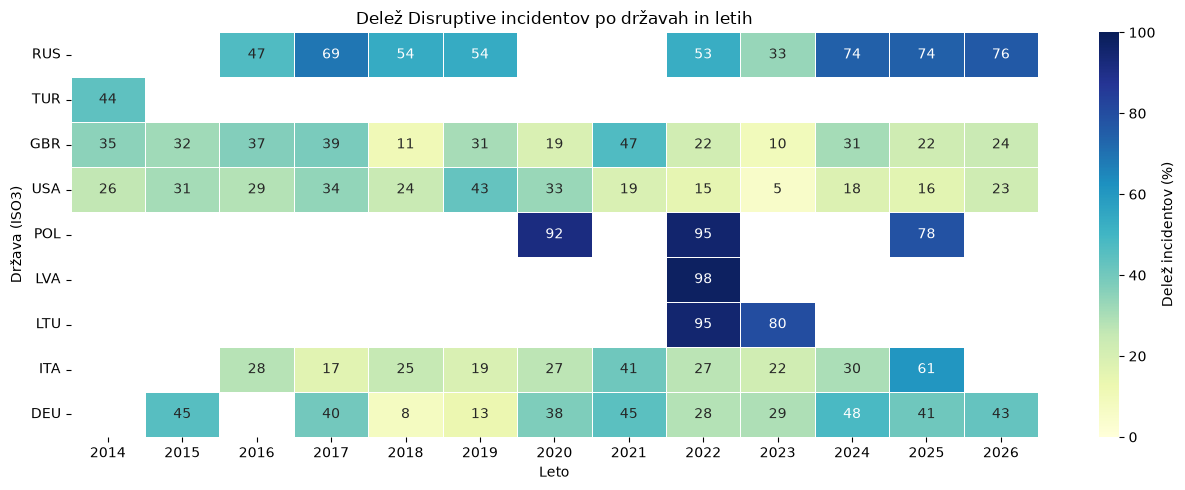

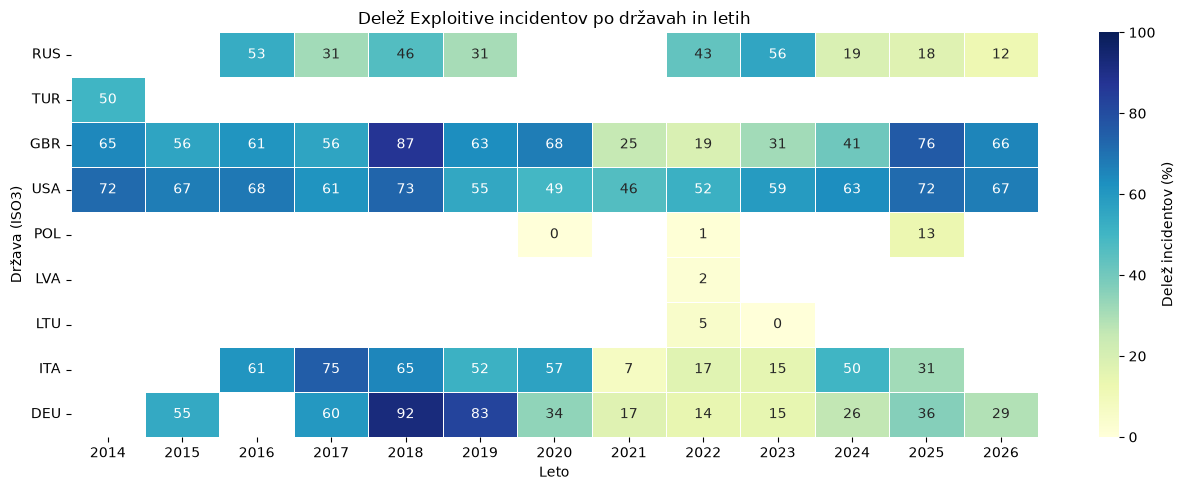

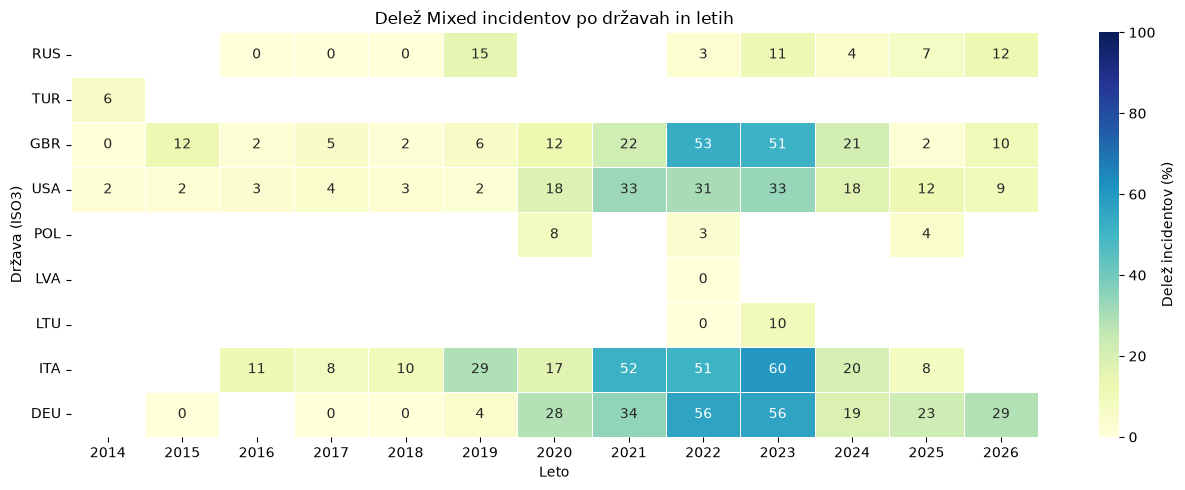

Kombinacije država–leto z manj kot 10 incidenti: 54


In [88]:
selected_countries = [
    "RUS", "TUR", "GBR", "USA", "POL",
    "LVA", "LTU", "ITA", "DEU"
]

# Število incidentov po državah in letih
data = df_viz[df_viz["country_iso3"].isin(selected_countries)]

year_country_counts = pd.crosstab(
    data["country_iso3"], data["year"]
)

# Deleži vrst incidentov znotraj države in leta
profiles = (
    data.groupby(["country_iso3", "year", "event_type"])
    .size()
    .unstack(fill_value=0)
)

profiles = profiles.div(profiles.sum(axis=1), axis=0) * 100

# Prikaz posameznih vrst incidentov
for event_type in ["Disruptive", "Exploitive", "Mixed"]:
    heatmap_data = (
        profiles[event_type]
        .unstack("year")
        .reindex(index=selected_countries, columns=sorted(data["year"].unique()))
    )

    # Skrijemo odstotke pri manj kot 10 incidentih
    insufficient = year_country_counts.reindex_like(heatmap_data) < 10

    fig, ax = plt.subplots(figsize=(13, 5))

    sns.heatmap(
        heatmap_data.astype(float),
        mask=insufficient,
        annot=True,
        fmt=".0f",
        cmap="YlGnBu",
        vmin=0,
        vmax=100,
        linewidths=0.5,
        cbar_kws={"label": "Delež incidentov (%)"},
        ax=ax
    )

    ax.set_title(f"Delež {event_type} incidentov po državah in letih")
    ax.set_xlabel("Leto")
    ax.set_ylabel("Država (ISO3)")
    ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()
    plt.show()

print("Kombinacije država–leto z manj kot 10 incidenti:",
      int((year_country_counts < 10).sum().sum()))


Nacionalni profili dokumentiranih kibernetskih incidentov se skozi čas različno spreminjajo. V ZDA prevladujejo izkoriščevalni incidenti, vendar se v obdobju 2020–2023 poveča delež mešanih incidentov. Podobne spremembe so izrazite pri Nemčiji, Italiji in Združenem kraljestvu, medtem ko v Rusiji v zadnjih letih naraste zastopanost motilnih incidentov. Pri državah z majhnim številom letnih zapisov časovnih vzorcev ni mogoče zanesljivo oceniti.

Ugotovitve kažejo, da je pri nadaljnjih primerjavah držav treba upoštevati časovno dimenzijo, ne samo skupnih deležev za celotno obdobje.


## 7. Ključne ugotovitve in možnosti nadaljnjega raziskovanja

### 7.1 Ključne ugotovitve

**Kakovost in omejitve podatkov**
- Zbirka UMD vsebuje 17.480 zapisov iz obdobja 2014–avgust 2026. Po standardizaciji in tehnični deduplikaciji je za začetne vizualizacije pripravljenih **17.353 zapisov**.
- Pri približno 57 % incidentov napadalec ni določen, pri približno 21 % pa ni določen motiv. Podatki o trajanju, obsegu in posledicah incidentov so večinoma manjkajoči.
- Zbirka je primerna predvsem za analizo vrst incidentov, podvrst, ciljnih sektorjev ter časovne in geografske porazdelitve. Število dokumentiranih incidentov ni neposredna mera dejanske kibernetske ogroženosti.

**Geografska in časovna pokritost**
- ZDA predstavljajo **49,2 %** geografsko določljivih incidentov. Deset najbolj zastopanih držav skupaj zajema **73,6 %** zapisov.
- Od 170 državnih kod jih ima 85 manj kot deset incidentov. Za podrobnejše statistične primerjave je zato treba upoštevati velikost vzorca.
- Največ incidentov je dokumentiranih v letih 2022 in 2023. Nacionalni profili incidentov se skozi čas spreminjajo, zato skupne primerjave držav za celotno obdobje niso vedno zadostne.

**Vrste incidentov in ciljni sektorji**
- Države imajo izrazito različne profile dokumentiranih incidentov. V Latviji, Litvi in Poljski prevladujejo motilni incidenti, pri čemer pomemben delež predstavlja `External Denial of Service`.
- V ZDA in nekaterih azijskih državah so bolj zastopani izkoriščevalni incidenti, predvsem `Exploitation of Application Server`.
- Pri dokumentiranih DDoS-podobnih incidentih je v nekaterih evropskih državah močno zastopana javna uprava, medtem ko v ZDA izstopajo tudi informacijske dejavnosti.
- Pri `Data Attack` se ciljni sektorji razlikujejo med državami. V ZDA izstopa zdravstvo, v Združenem kraljestvu pa izobraževanje.
- V obdobju 2020–2023 se v več državah poveča delež incidentov `Mixed`. Možna povezava z izsiljevalskimi napadi zahteva dodatno preverjanje z ustrezno klasificiranimi podatki.

### 7.2 Zanimiva vprašanja za nadaljnjo analizo

**Vrste in podvrste incidentov**

1. Zakaj so DDoS-podobni incidenti posebej zastopani v Latviji, Litvi in Poljski? Ali so skoncentrirani v določenih letih, sektorjih ali povezanih kampanjah?

2. Ali so DDoS-podobni napadi v evropskih državah pogosteje usmerjeni proti javni upravi kot v ZDA?

3. Ali je povečanje deleža `Mixed` v obdobju 2020–2023 povezano z ransomware in dvojnim izsiljevanjem?

**Ciljni sektorji**
4. Zakaj je med dokumentiranimi podatkovnimi napadi v Združenem kraljestvu izrazito zastopano izobraževanje? Ali gre za določeno obdobje, vrsto organizacij ali kampanjo?

5. Ali so napadi na podatke v zdravstvu v ZDA bolj zastopani kot v primerljivih evropskih državah?

6. Ali se delež incidentov, usmerjenih v proizvodnjo, finance ali zdravstvo, povezuje z gospodarsko strukturo države?

**Gospodarski in digitalni dejavniki**
7. Ali so razlike v vrstah incidentov povezane z BDP na prebivalca in stopnjo digitalizacije?

8. Ali države s podobno gospodarsko razvitostjo, vendar različno kibernetsko pripravljenostjo, izkazujejo različne profile incidentov?

9. Ali obstajajo države, katerih profili incidentov izrazito odstopajo od držav s podobnimi gospodarskimi in digitalnimi značilnostmi?



**Naslednja raziskovalna naloga je ugotoviti, kateri gospodarski, digitalni, varnostni ali drugi dejavniki so povezani s temi razlikami.**
